# Predicting COVID-19 from symptoms across countries

`notebook.ipynb` reproduced Zoabi et al. (2021) on the Israeli data and found its main weakness: **reporting bias**. Symptoms were recorded far more thoroughly for people who tested positive. This notebook asks whether the paper's approach holds up on data from other countries, where symptoms were recorded before the result was known, and whether combining countries helps.

**Contents**
1. **The `symptompred` library**: the conventions and tools used throughout
2. **The datasets**: Israel, the US (Carbon Health) and Brazil (e-SUS Notifica), one at a time
3. **Comparing the datasets**: features, reporting bias, symptom profiles, and what "missing" means
4. **Experiments**: modelling each dataset; training on one and testing on another; pooling datasets
5. **Summary**

Every section loops over whichever datasets are loaded, so the Brazil data appears automatically once it has been downloaded (see 2.3).

In [1]:
%load_ext autoreload
%autoreload 2

import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import shap

import symptompred as sp

pd.set_option("display.max_columns", None)
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
COLORS = {"israel": BLUE, "carbon_health": ORANGE, "brazil": AQUA}   # one colour per dataset, used everywhere
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

---
# 1. The `symptompred` library

Each dataset arrives in its own format: different column names, codes, languages and quirks. The paper's code only works on the Israeli layout. `symptompred` (in `symptompred/` in this repo) separates the two concerns, much as Prophet does for time series:

1. **One data convention.** Every dataset is converted into the same shape.
2. **One set of tools** (model, evaluation, experiments) that only ever sees that shape.

So adding a country means writing one loader. Everything else works unchanged.

## 1.1 The data convention

One row per test:

| column | required | values | meaning |
|---|---|---|---|
| `date` | yes | date | when the test was taken (used for time-based splits) |
| `y` | yes (to train or evaluate) | 0 / 1 | test result, 1 = positive |
| feature columns | at least one | 1, 0 or NaN | from the vocabulary below; NaN = not recorded for this person |
| `source` | no | text | which dataset the row came from (needed when pooling) |
| `age`, `region` | no | number / text | kept for reference; not used by the model |

A feature a dataset **never collected** is left out entirely rather than included as an all-NaN column. This lets the library tell "this country never asked" apart from "this person's answer is missing". The distinction matters in section 3.4.

In [2]:
print("Paper's 8 features:   ", sp.CORE_FEATURES)
print("Extra features:       ", sp.EXTRA_FEATURES)
print("Demographic (never assumed 'absent'):", sp.DEMOGRAPHIC_FEATURES)

Paper's 8 features:    ('cough', 'fever', 'sore_throat', 'shortness_of_breath', 'headache', 'age_60', 'male', 'contact')
Extra features:        ('loss_of_smell', 'loss_of_taste', 'runny_nose', 'fatigue', 'muscle_ache', 'diarrhoea')
Demographic (never assumed 'absent'): ('age_60', 'male')


`sp.validate(df)` checks a DataFrame against the convention and gives a clear error if something's wrong (unknown columns, non-binary features, missing dates):

In [3]:
try:
    sp.validate(pd.DataFrame({"date": ["2020-04-01"], "y": [1], "temperature": [38.2]}))
except sp.SchemaError as e:
    print("SchemaError:", e)

SchemaError: No feature columns found. Use names from symptompred.ALL_FEATURES: ('cough', 'fever', 'sore_throat', 'shortness_of_breath', 'headache', 'age_60', 'male', 'contact', 'loss_of_smell', 'loss_of_taste', 'runny_nose', 'fatigue', 'muscle_ache', 'diarrhoea')


## 1.2 Loaders

| Dataset | Loader | Raw data |
|---|---|---|
| Israel (the paper) | `sp.datasets.israel.load()` | `covidpred-master/data/` |
| US: Carbon Health | `sp.datasets.carbon_health.load()` | `covidclinicaldata-master/data/` |
| Brazil: e-SUS Notifica | `sp.datasets.brazil.load()` | `data/brazil/`, filled by `scripts/download_brazil.py` |

Each loader's docstring lists its mapping decisions (e.g. `help(sp.datasets.brazil)`). Adding a new dataset looks like this:

```python
def load_my_country(path):
    raw = pd.read_csv(path)
    return sp.validate(pd.DataFrame({
        "date": pd.to_datetime(raw["test_date"]),
        "y": (raw["result"] == "POS").astype(int),
        "cough": raw["has_cough"].map({"Y": 1, "N": 0}),
        # ... any other features from sp.ALL_FEATURES ...
        "source": "my_country",
    }))
```

Loading everything we have. Brazil is optional, and the `BRAZIL_DIR` environment variable can point at the data if it lives somewhere else:

In [4]:
DATASETS = {
    "israel": sp.datasets.israel.load(drop_unknown_sex=True),   # the paper's filtering
    "carbon_health": sp.datasets.carbon_health.load(),
}
BRAZIL_DIR = Path(os.environ.get("BRAZIL_DIR", sp.datasets.brazil.DATA_DIR))
brazil_raw = None
if sp.datasets.brazil.available(BRAZIL_DIR):
    brazil_raw = sp.datasets.brazil.read_raw(BRAZIL_DIR)
    DATASETS["brazil"] = sp.datasets.brazil.load(raw=brazil_raw)
else:
    print(f"No Brazil data in {BRAZIL_DIR}: run `python scripts/download_brazil.py`, then rerun the notebook.")

for name, df in DATASETS.items():
    print(f"{name:14s} {len(df):>9,} tests, {df.y.mean():6.2%} positive, "
          f"{df.date.min():%d %b %Y} to {df.date.max():%d %b %Y}, {len(sp.available_features(df))} features")

israel           255,911 tests,  5.30% positive, 22 Mar 2020 to 30 Apr 2020, 8 features
carbon_health     93,995 tests,  1.40% positive, 07 Apr 2020 to 20 Oct 2020, 13 features
brazil            98,095 tests, 43.05% positive, 14 Mar 2020 to 29 Dec 2022, 10 features


## 1.3 The model

`sp.SymptomModel` is the paper's method (LightGBM with the authors' hyperparameters), wrapped so it works on any dataset in the convention:

| Option | Default | What it does |
|---|---|---|
| `features` | `"core"` | `"core"` = the paper's 8 (whichever the data has), `"all"` = plus extras, or a list |
| `missing` | `"native"` | `"native"` = LightGBM learns from blanks (paper). `"absent"` = an unrecorded symptom or contact counts as "not reported" (see 3.4) |
| `n_models` | `1` | average this many models trained on different seeds (more = more stable) |
| `early_stopping_rounds` | `50` | paper used 5, which made results swing between 0.76 and 0.90 depending on the seed |
| `fit(df, sample_weight=...)` | `None` | `"balance_sources"` gives each dataset equal total weight when pooling |

`sp.SymptomModel.paper()` gives the exact original settings.

| Method | Returns |
|---|---|
| `fit(df)` | the fitted model |
| `predict(df)` | probability of a positive test |
| `evaluate(df, bootstrap=1000, sensitivity=None)` | auROC, auPRC, Brier score, CIs, optional working point |
| `shap_values(df)` | SHAP explanation for `shap.plots.*` |

## 1.4 Experiment helpers

| Function | Does |
|---|---|
| `sp.temporal_split(df)` / `sp.date_split(df, train, test)` | prospective train/test splits, like the paper |
| `sp.feature_summary(datasets)` / `sp.common_features(...)` | which features each dataset has |
| `sp.pool(datasets)` | stack datasets into one, labelled by `source` |
| `sp.compare(datasets, splits=...)` | train on each dataset, test on its own later period and on every other dataset |
| `sp.leave_one_out(datasets, splits=...)` | pool all-but-one dataset, test on the one left out |
| `sp.forward_selection(train, test)` | add features one at a time, best first: "how many questions do we need?" |
| `sp.pivot(results)` | matrix view of `compare` output |
| `sp.plot_curves({label: (y, p)})` | ROC + precision–recall curves for several models on one test set |
| `sp.plot_curve_grid({test: {label: (y, p)}})` | the same, one column per test set |
| `sp.plot_shap_grid({name: model.shap_values(df)})` | SHAP beeswarms side by side, with the same features in the same order |

`compare` and `leave_one_out` keep each model's test predictions in `results.attrs["predictions"]`, so curves can be drawn without retraining.

## 1.5 Check: does it reproduce the paper?

In [5]:
isr_train, isr_test = sp.date_split(DATASETS["israel"], sp.datasets.israel.PAPER_TRAIN, sp.datasets.israel.PAPER_TEST)
paper_model = sp.SymptomModel().fit(isr_train)
paper_model.evaluate(isr_test, sensitivity=0.873)[
    ["n", "positives", "auroc", "auroc_lo", "auroc_hi", "wp_sensitivity", "wp_specificity"]].round(4)

n                 47401.0000
positives          3624.0000
auroc                 0.9016
auroc_lo              0.8951
auroc_hi              0.9081
wp_sensitivity        0.8731
wp_specificity        0.7199
dtype: float64

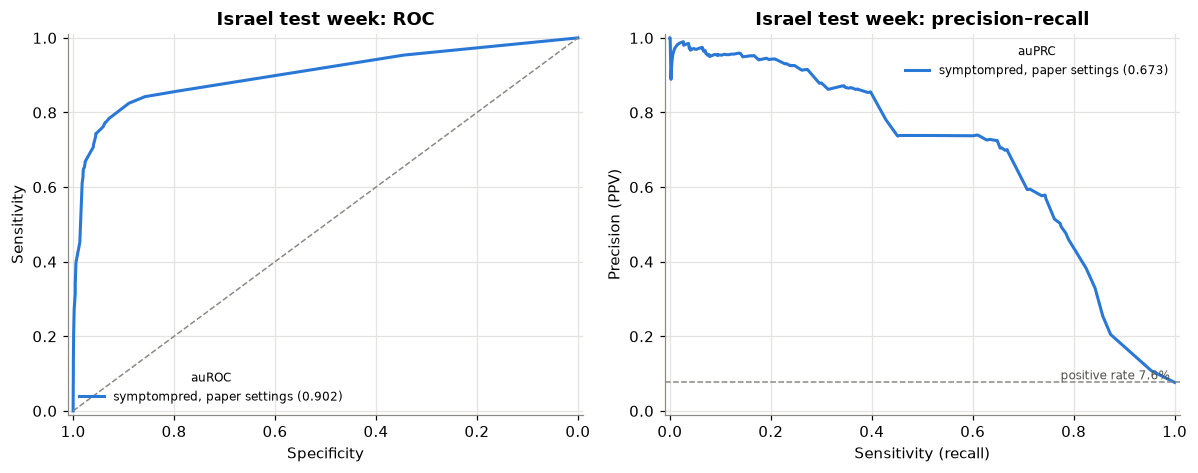

In [6]:
sp.plot_curves({"symptompred, paper settings": (isr_test.y.values, paper_model.predict(isr_test))},
               colors={"symptompred, paper settings": BLUE}, title="Israel test week")
plt.tight_layout()

auROC 0.90 (paper: 0.90, CI 0.892–0.905) and the paper's exact working point of 87.3% sensitivity / 72.0% specificity. The curves correspond to the paper's Fig. 1. The ROC curve is a staircase: 8 yes/no answers allow at most 256 distinct inputs, so there are only a few dozen possible thresholds. Precision stays above 90% for the top-ranked third of positives (mostly known contacts and people with the "biased" symptoms), then falls.

---
# 2. The datasets

Each dataset gets a **standard prospective split**: train on an earlier period, test on a later one, as the paper did. The same splits are used in every experiment.

In [7]:
def brazil_split(df):
    """Train on 2020–21, test on 2022 (falls back to the latest 20% if 2022 isn't downloaded yet)."""
    tr, te = sp.date_split(df, ("2020-01-01", "2021-12-31"), ("2022-01-01", "2022-12-31"))
    return (tr, te) if len(te) and te.y.nunique() == 2 else sp.temporal_split(df)

SPLITS = {
    "israel": (isr_train, isr_test),   # the paper: 22–31 Mar 2020 / 1–7 Apr 2020
    "carbon_health": sp.date_split(DATASETS["carbon_health"], ("2020-04-01", "2020-08-31"), ("2020-09-01", "2020-10-31")),
}
if "brazil" in DATASETS:
    SPLITS["brazil"] = brazil_split(DATASETS["brazil"])

pd.DataFrame({
    name: {"train from": tr.date.min().date(), "train to": tr.date.max().date(), "train tests": len(tr),
           "train positives": tr.y.sum(), "test from": te.date.min().date(), "test to": te.date.max().date(),
           "test tests": len(te), "test positives": te.y.sum()}
    for name, (tr, te) in SPLITS.items()
}).T

,train from,train to,train tests,train positives,test from,test to,test tests,test positives
israel,2020-03-22,2020-03-31,51831,4769,2020-04-01,2020-04-07,47401,3624
carbon_health,2020-04-07,2020-08-25,44409,960,2020-09-01,2020-10-20,49586,353
brazil,2020-03-14,2021-12-31,89752,38312,2022-01-01,2022-12-29,8343,3919


## 2.1 Israel (the paper's data)

Covered in depth in `notebook.ipynb`. In brief:
- **What:** every RT-PCR test reported by the Israeli Ministry of Health, 11 March – 30 April 2020 (`ver_006`). Sex isn't recorded before 22 March, so after the paper's filtering the data runs 22 March – 30 April.
- **Features:** the paper's 8. Contact comes from `test_indication`, i.e. the official reason for the test.
- **Filtering:** inconclusive results and unknown sex dropped (the latter reproduces the paper's row counts exactly).
- **Known issues:**
  - Symptoms were recorded more thoroughly for positives (3.2).
  - Age is missing for nearly half the rows, unevenly by outcome after the paper's window.
  - The tested population changes quickly as testing scales up.

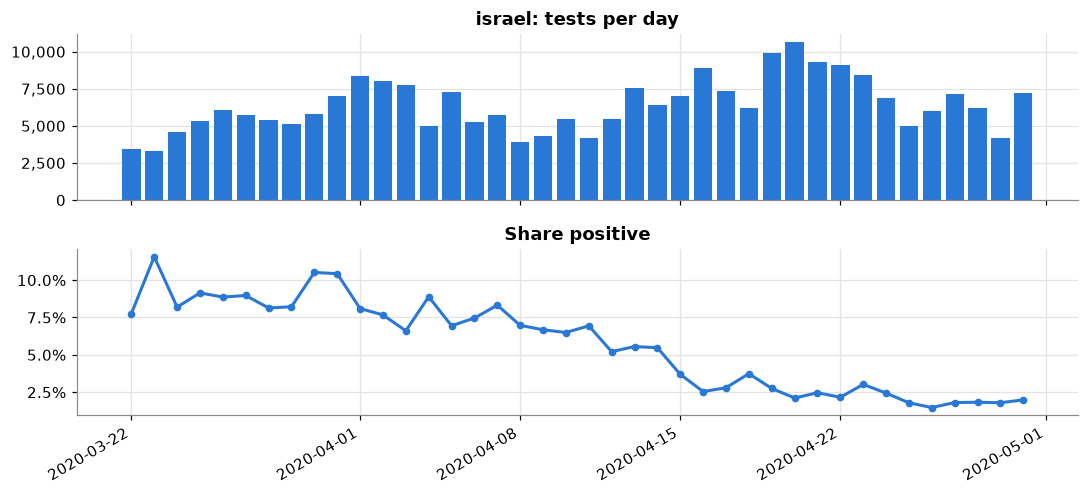

In [8]:
def daily_summary(df, freq):
    g = df.set_index("date").resample(freq).y
    return pd.DataFrame({"tests": g.size(), "positivity": g.mean()})

def plot_volume_and_positivity(df, name, freq, title_unit):
    s = daily_summary(df, freq)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
    ax1.bar(s.index, s.tests, width={"D": 0.8, "W": 5, "MS": 25}[freq], color=COLORS[name])
    ax1.set_title(f"{name}: tests per {title_unit}")
    ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax2.plot(s.index, s.positivity, color=COLORS[name], linewidth=2, marker="o", markersize=4)
    ax2.set_title("Share positive")
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    fig.autofmt_xdate()
    plt.tight_layout()

plot_volume_and_positivity(DATASETS["israel"], "israel", "D", "day")

## 2.2 US: Carbon Health

- **What:** de-identified records of every COVID-19 test at Carbon Health's US walk-in clinics, March–October 2020, published in weekly batches ([repository](https://github.com/mdcollab/covidclinicaldata), CC BY-NC-SA). Symptoms and exposure were recorded **at the visit, before the result**.
- **Features:** 7 of the paper's 8 (**no sex field**), plus loss of smell, loss of taste, runny nose, fatigue, muscle ache and diarrhoea. Contact = `high_risk_interactions` ("may have been exposed through contact with a known infected person").
- **Caveats:**
  - Only the week of the test is known (`batch_date`), not the day.
  - Ages are noise-added by the publisher.
  - The publishers warn collection is "clinically driven and not systematic".

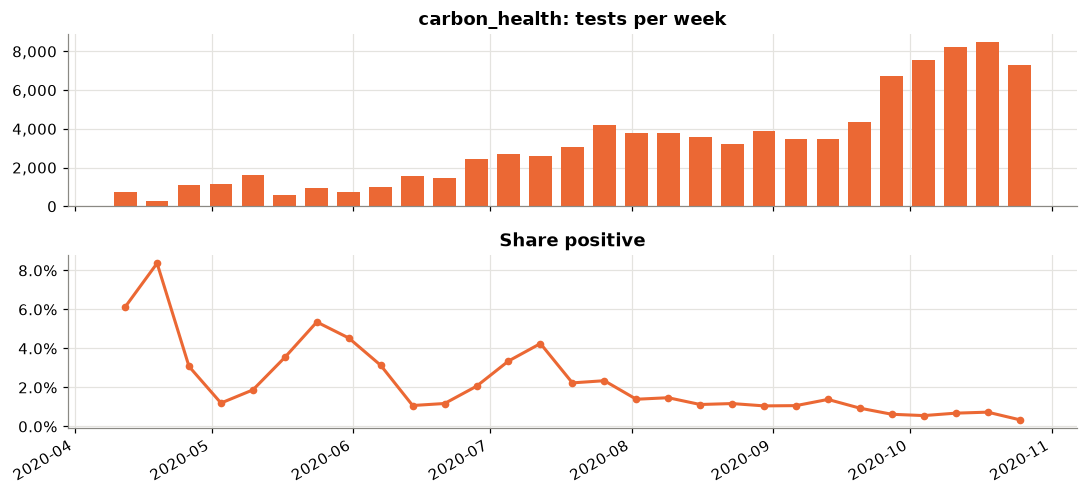

In [9]:
plot_volume_and_positivity(DATASETS['carbon_health'], 'carbon_health', 'W', 'week')

Volume grows ~10x while positivity falls from ~6–8% in April to under 1% by October. Early on these are mostly symptomatic patients. Later it's increasingly routine screening (pop-up and mobile clinics, home kits), so the population being tested shifts a lot.

Test types: almost all molecular (PCR / NAAT). The ambiguous "Rapid COVID-19 Test" (~4%) can be dropped with `load(molecular_only=True)`.

In [10]:
sp.datasets.carbon_health.read_raw().groupby("test_name").covid19_test_results.agg(
    tests="size", positivity=lambda s: (s == "Positive").mean()
).sort_values("tests", ascending=False).style.format({"tests": "{:,}", "positivity": "{:.2%}"})

,tests,positivity
test_name,,
"SARS-CoV-2, NAA","48,932",1.62%
Rapid COVID-19 PCR Test,"26,805",0.28%
SARS COV2 NAAT,"6,365",4.70%
COVID-19 PCR External Result,"5,998",0.12%
Rapid COVID-19 Test,"3,714",2.13%
COVID-19 Vitagene At Home Test Kit,839,0.72%
"SARS-CoV-2 (COVID-19) by NAAT/RT-PCR/TMA, Unknown Risk",590,1.02%
SARS CoV w/CoV 2 RNA,396,5.81%
SARS COV 2 RNA RTPCR,354,7.06%


## 2.3 Brazil: e-SUS Notifica

- **What:** Brazil's national notifications of mild flu-like illness (*síndrome gripal*), 2020–2022, from the Ministry of Health's open-data API. Download with `python scripts/download_brazil.py` (resumable; see its `--help`).
- **Features:** 7 of the paper's 8 (**no contact field**), plus loss of smell, loss of taste and runny nose. Symptoms come from a checklist filled in at notification, which includes an explicit "asymptomatic" option.
- **Filtering:** only notifications with an **RT-PCR** result. Many tests in this system are rapid antibody tests, which show past infection rather than current infection.
- **Caveats:**
  - The API serves only a **non-random slice** of the national data (~600k notifications across three years; see below).
  - Dates need cleaning: the loader falls back to the notification date when the test date is implausible, and drops the handful outside Feb 2020 – Dec 2022.

In [11]:
if brazil_raw is not None:
    first_test = brazil_raw["codigo_tipo_teste_1"].map(sp.datasets.brazil.TEST_TYPES).fillna("none recorded")
    has_result = brazil_raw["codigo_resultado_teste_1"].isin(["1", "2"])
    display(pd.DataFrame({"notifications": first_test.value_counts(),
                          "with a conclusive result": first_test[has_result].value_counts()})
            .fillna(0).astype(int).sort_values("notifications", ascending=False)
            .style.format("{:,}").set_caption("Most recent test type per notification (all downloaded rows)"))
    print(f"Kept for modelling (RT-PCR with a result): {len(DATASETS['brazil']):,} of {len(brazil_raw):,} notifications")
else:
    print("Brazil not loaded yet.")

,notifications,with a conclusive result
codigo_tipo_teste_1,,
rapid antigen,"246,170","218,675"
RT-PCR,"154,698","97,273"
rapid antibody IgG,"118,022","114,777"
none recorded,"56,960","1,171"
serology IgG,"13,597","12,320"
rapid antibody IgM,"6,134","6,014"
serology IgM,"3,138","2,718"
serology total antibodies,"1,569","1,223"
RT-LAMP,56,33


Kept for modelling (RT-PCR with a result): 98,095 of 600,366 notifications


,tests,positivity
region,,
Acre,"97,092",43.1%
São Paulo,255,39.2%
Amazonas,239,36.4%
Rondônia,214,57.0%
Minas Gerais,92,37.0%
Rio de Janeiro,48,45.8%
Pernambuco,33,18.2%
Paraná,20,35.0%
Distrito Federal,14,50.0%


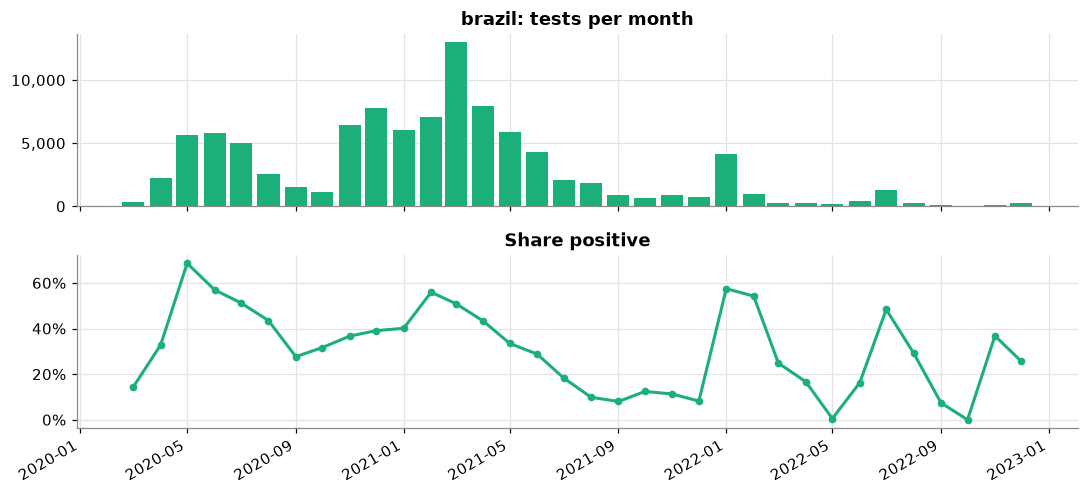

In [12]:
if "brazil" in DATASETS:
    plot_volume_and_positivity(DATASETS["brazil"], "brazil", "MS", "month")
    display(DATASETS["brazil"].groupby("region").y.agg(tests="size", positivity="mean")
            .sort_values("tests", ascending=False).head(10).style.format({"tests": "{:,}", "positivity": "{:.1%}"})
            .set_caption("Top 10 states by RT-PCR tests"))

- **Only ~1 in 6 notifications is usable.** The most recent test is usually a rapid antigen or antibody test. RT-PCR with a result leaves **98k tests**.
- **This isn't really "Brazil".** About **99% of the RT-PCR tests come from one state, Acre** (population ~900k, in the Amazon). Ages are also cut off in the mid-50s: there's essentially **nobody aged 60+** (none in 2020, one in 2021), so `age_60` carries no information here. The API serves a narrow slice of the national data. A fair label for this dataset is "under-55s tested in Acre".
- **Positivity is very high (~43%).** This system records people with flu-like illness, and RT-PCR went mostly to symptomatic people, so testing is targeted, unlike Carbon Health's screening.
- **2022 is small and different.** Rapid antigen tests largely replaced PCR, leaving ~8k PCR tests. Waves show as positivity swings (the Omicron spike in January 2022). Loss of smell, a hallmark of earlier variants, became rare (see 4.1).

---
# 3. Comparing the datasets

## 3.1 What each dataset collected

Share of rows with each feature recorded (— = never collected):

In [13]:
sp.feature_summary(DATASETS).style.format('{:.0%}', na_rep='—')

,israel,carbon_health,brazil
cough,100%,100%,100%
fever,100%,76%,100%
sore_throat,100%,100%,100%
shortness_of_breath,100%,100%,100%
headache,100%,100%,100%
age_60,53%,100%,77%
male,100%,—,100%
contact,100%,74%,—
loss_of_smell,—,100%,100%
loss_of_taste,—,100%,100%


In [14]:
print('Features every dataset shares:', sp.common_features(*DATASETS.values()))

Features every dataset shares: ['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'headache', 'age_60']


No dataset has everything. Carbon Health lacks sex, Brazil lacks contact, and Israel lacks loss of smell/taste. The more datasets we add, the smaller the set they all share. Across all three it's just the five symptoms and age ≥ 60, and age is meaningless in the Brazil slice. This is why section 4 also tries **pooling**, which can use every feature any dataset has.

## 3.2 Reporting bias

The paper called a symptom "biased" when nearly everyone recorded with it tested positive, a sign it was mainly being written down for confirmed cases. Here's the same measure for each dataset, alongside the overall positive rate for scale:

In [15]:
SYMPTOMS = ["cough", "fever", "sore_throat", "shortness_of_breath", "headache", "loss_of_smell", "loss_of_taste"]

def pct_positive_if_present(d, feats):
    return pd.Series({f: d.loc[d[f] == 1, "y"].mean() if f in sp.available_features(d) else np.nan for f in feats})

bias = pd.DataFrame({name: pct_positive_if_present(d, SYMPTOMS + ["contact"]) for name, d in DATASETS.items()})
bias.loc["(overall positive rate)"] = [d.y.mean() for d in DATASETS.values()]
bias.style.format("{:.1%}", na_rep="—").set_caption("% positive among people recorded with each feature")

,israel,carbon_health,brazil
cough,15.5%,6.8%,48.5%
fever,25.4%,10.9%,49.6%
sore_throat,90.9%,3.5%,43.7%
shortness_of_breath,90.8%,3.7%,47.3%
headache,95.4%,5.4%,41.8%
loss_of_smell,—,23.8%,69.6%
loss_of_taste,—,20.7%,65.0%
contact,71.3%,1.5%,—
(overall positive rate),5.3%,1.4%,43.1%


- **Israel:** 91–95% of people recorded with headache, sore throat or shortness of breath were positive, against a 5% base rate. Those symptoms were essentially only written down for confirmed cases.
- **Carbon Health:** only 3–11% of people with any of the paper's five symptoms were positive. Symptoms were recorded for everyone, so there's no sign of the same bias.
- **Brazil:** 42–50% of people with each symptom were positive, almost exactly the 43% base rate. No reporting bias, but symptoms barely tell positives from negatives, because almost everyone in this system is ill with *something*.

Because base rates differ, **lift** is the fairer comparison: positivity when the feature is present ÷ positivity when it's absent (1x = no signal).

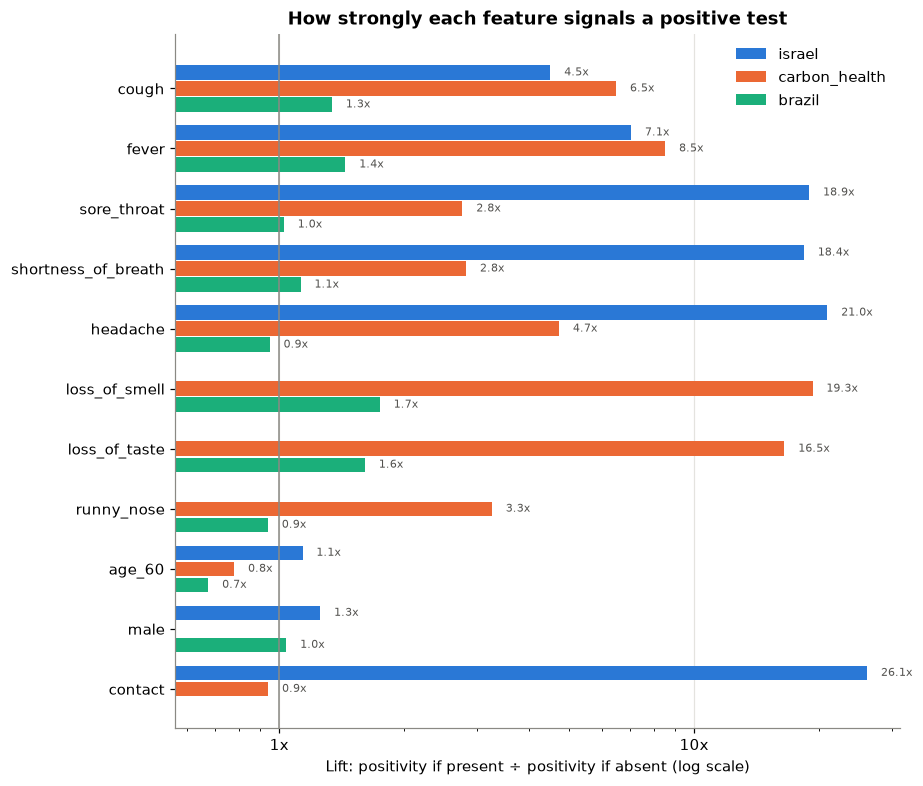

In [16]:
def lift(d, feats):
    out = {}
    for f in feats:
        if f in sp.available_features(d):
            out[f] = d.loc[d[f] == 1, "y"].mean() / d.loc[d[f] == 0, "y"].mean()
    return pd.Series(out, dtype=float).reindex(feats)

LIFT_FEATURES = SYMPTOMS + ["runny_nose", "age_60", "male", "contact"]
lifts = pd.DataFrame({name: lift(d, LIFT_FEATURES) for name, d in DATASETS.items()})

fig, ax = plt.subplots(figsize=(8.5, 0.55 * len(lifts) + 1.2))
n = len(DATASETS)
height = 0.8 / n
for j, name in enumerate(DATASETS):
    offset = (j - (n - 1) / 2) * height
    vals = lifts[name]
    ax.barh(np.arange(len(lifts)) + offset, vals, height=height * 0.9, color=COLORS[name], label=name)
    for i, v in enumerate(vals):
        if pd.notna(v):
            ax.text(v * 1.08, i + offset, f"{v:.1f}x", va="center", fontsize=7.5, color="#52514e")
ax.set_xscale("log")
ax.axvline(1, color=GREY, linewidth=1)
ax.set_yticks(range(len(lifts)), lifts.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}x"))
ax.set_xlabel("Lift: positivity if present ÷ positivity if absent (log scale)")
ax.set_title("How strongly each feature signals a positive test")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()

- **The "biased" trio collapses** outside Israel. Headache, sore throat and shortness of breath fall from ~18–21x in Israel to ~3–5x in Carbon Health. That supports the paper's suspicion that their strength in Israel was mostly a recording artefact.
- **Cough and fever** stay strong (~5–9x). The paper classed these as "balanced".
- **Loss of smell and taste** are the strongest symptoms wherever they were collected (~17–19x in Carbon Health).
- **Contact** goes from ~26x in Israel to no signal at all in Carbon Health (~0.9x). In Israel it was the official *reason for the test*; in Carbon Health it's a self-reported "may have been exposed". Same name, different measurement.
- **Brazil's lifts are all close to 1x** (0.9–1.7x). Among people who are all ill, COVID and other respiratory infections look alike. Loss of smell/taste, fever and cough are the only modest signals. Headache and runny nose point slightly *away* from COVID (more typical of colds and flu).
- **Age ≥ 60 and sex** are weak everywhere. Brazil's age lift rests on a few hundred people and should be ignored.

## 3.3 How many positives had no symptoms?

In [17]:
def n_symptoms_table(d):
    n = d[["cough", "fever", "sore_throat", "shortness_of_breath", "headache"]].sum(axis=1, min_count=1).clip(upper=3)
    t = pd.crosstab(n, d.y.map({0: "negative", 1: "positive"}), normalize="columns")
    t.index = [{0: "0", 1: "1", 2: "2", 3: "3+"}[int(i)] for i in t.index]
    return t

pd.concat({name: n_symptoms_table(d) for name, d in DATASETS.items()}, axis=1).style.format("{:.0%}")\
    .set_caption("Number of the paper's 5 symptoms reported, by test result")

About a third of Israeli positives and about half of Carbon Health positives reported **none** of the five symptoms. Those cases (largely found through contact tracing or screening) are out of reach for any symptom-based model, which caps how well it can do.

Brazil is the opposite: only 7% of positives and 14% of negatives report no symptoms. Everyone is symptomatic, so the question becomes "which kind of respiratory illness is this?", which is much harder for five yes/no questions.

## 3.4 What does "not recorded" mean?

Missing values aren't always random. In the Israeli data, age was missing far more often for negatives (see `notebook.ipynb` §12). For each dataset, here's how positivity differs between people with a field **recorded** and **not recorded**, in the training period and the test period:

In [18]:
rows = []
for name, (tr, te) in SPLITS.items():
    for f in sp.available_features(DATASETS[name]):
        if max(tr[f].isna().mean(), te[f].isna().mean()) < 0.01:   # skip features that are (almost) never blank
            continue
        for period, d in [("train", tr), ("test", te)]:
            missing = d[f].isna()
            rows.append({"dataset": name, "feature": f, "period": period, "% not recorded": missing.mean(),
                         "positivity if recorded": d.loc[~missing, "y"].mean(),
                         "positivity if not recorded": d.loc[missing, "y"].mean()})
miss = pd.DataFrame(rows)
miss["ratio (not ÷ recorded)"] = miss["positivity if not recorded"] / miss["positivity if recorded"]
miss.set_index(["dataset", "feature", "period"]).style.format("{:.2%}").format("{:.2f}x", subset=["ratio (not ÷ recorded)"])

Israel doesn't appear: within the paper's windows its features are essentially never blank (the age gaps come later in April). Brazil's only partly-blank feature is age (22–26% missing), which shows a mild flip (1.09x → 0.91x), small enough to matter little. Its symptoms come from a checklist and are never blank.

**Carbon Health shows the problem clearly.** For fever and contact:
- In the **training period** (Apr–Aug), tests with the field *not recorded* were **~2.4x more** likely positive.
- In the **test period** (Sep–Oct), they were **~3–4x less** likely positive.

The meaning of a blank flipped. Blanks mark the **testing setting**, not the patient. Early on, busy clinics seeing sick people; later, pop-up and home-kit screening of mostly healthy people, where no clinician records vitals. A model that learns "blank = higher risk" in spring gets autumn backwards.

This is why `SymptomModel` has `missing="absent"`. It treats an unrecorded *symptom or contact* as "not reported" (0), so blanks can't become a signal. Age and sex stay genuinely unknown, and features a dataset never collected are never filled. Section 4.1 tests whether this helps.

---
# 4. Experiments

All experiments use the splits from section 2, average 5 models per configuration (`n_models=5`) for stability, and report auROC (the paper's metric) with bootstrap 95% CIs where shown.

## 4.1 Modelling each dataset on its own

For each dataset: the paper's features (`core`) vs every feature it has (`all`), and missing values handled the paper's way (`native`) vs `missing="absent"`.

In [19]:
rows, within_preds = [], {}
for name, (tr, te) in SPLITS.items():
    for features in ["core", "all"]:
        for missing in ["native", "absent"]:
            m = sp.SymptomModel(features=features, missing=missing, n_models=5).fit(tr)
            within_preds[(name, features, missing)] = (te.y.values, m.predict(te))
            r = m.evaluate(te, bootstrap=300)
            rows.append({"dataset": name, "features": f"{features} ({len(m.features_)})", "missing": missing,
                         "auroc": r.auroc, "lo": r.auroc_lo, "hi": r.auroc_hi, "auprc": r.auprc})
within = pd.DataFrame(rows)
within.set_index(["dataset", "features", "missing"]).style.format("{:.3f}")

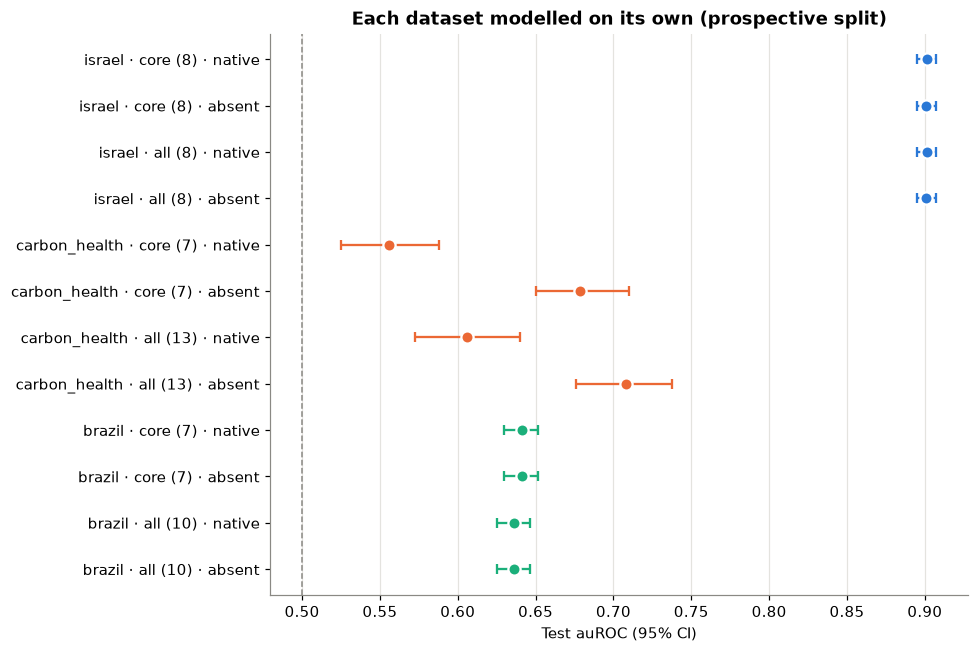

In [20]:
fig, ax = plt.subplots(figsize=(9, 0.42 * len(within) + 1))
labels = [f"{r.dataset} · {r.features} · {r.missing}" for r in within.itertuples()]
for i, r in enumerate(within.itertuples()):
    ax.errorbar(r.auroc, i, xerr=[[r.auroc - r.lo], [r.hi - r.auroc]], fmt="o", color=COLORS[r.dataset],
                markersize=8, markeredgecolor="white", markeredgewidth=1.5, capsize=3)
ax.set_yticks(range(len(labels)), labels)
ax.invert_yaxis()
ax.axvline(0.5, color=GREY, linestyle="--", linewidth=1)
ax.set_xlabel("Test auROC (95% CI)")
ax.set_title("Each dataset modelled on its own (prospective split)")
ax.grid(axis="y", visible=False)
plt.tight_layout()

ROC and precision–recall curves for the paper's settings (`core`, `native`) and the best settings (`all`, `absent`) on each dataset's test period:

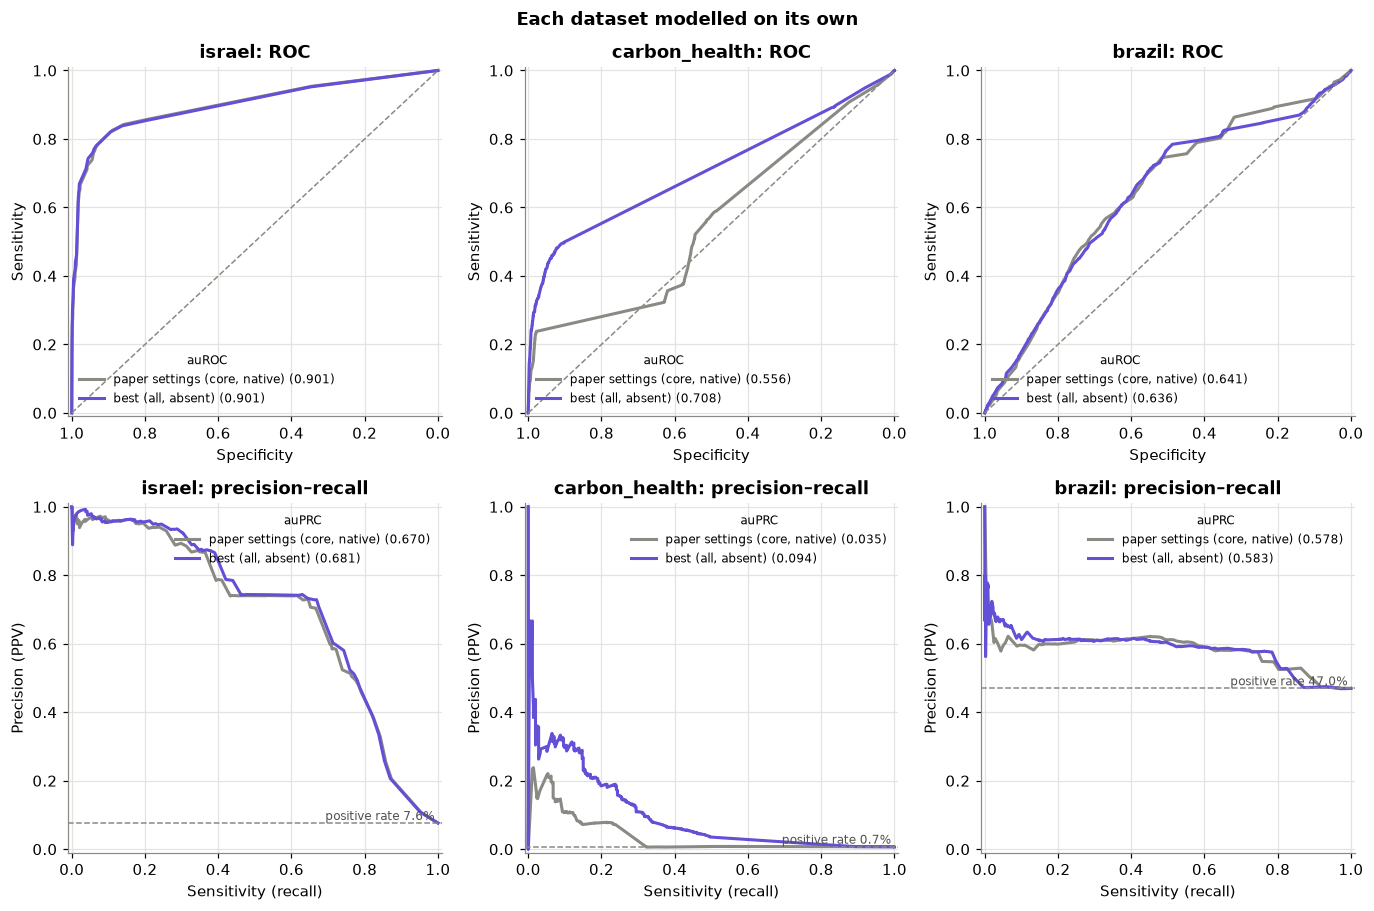

In [21]:
PAPER_LABEL, BEST_LABEL = "paper settings (core, native)", "best (all, absent)"
sp.plot_curve_grid(
    {name: {PAPER_LABEL: within_preds[(name, "core", "native")], BEST_LABEL: within_preds[(name, "all", "absent")]}
     for name in SPLITS},
    colors={PAPER_LABEL: GREY, BEST_LABEL: "#6250d6"},
    suptitle="Each dataset modelled on its own",
);

- **Israel: 0.90 whatever the settings.** Its symptoms are almost never blank, so the missing-value setting makes no difference, and it has no extra features to add.
- **Carbon Health is much harder: 0.56–0.71.** Both options matter:
  - `missing="absent"` adds **~0.10–0.12**. Stopping the model from learning "blank = clinic type" (3.4) is the single biggest improvement.
  - The extra symptoms (`all`) add **~0.03–0.05**, mostly loss of smell and taste.
- The best Carbon Health model (all features, `absent`: **0.708**) is still far below Israel. With less reporting bias and half of positives having no symptoms, ~0.7 looks like a realistic level for symptom-only prediction.
- **The curves** show where the Carbon Health gain comes from. At ~90% specificity, the best model finds about half of positives, against about a quarter with the paper's settings. Precision depends heavily on the base rate: Carbon Health's best model peaks around 30% precision (base rate 0.7%), while Brazil's curves sit only modestly above its 47% base rate.
- **Brazil: ~0.64**, the lowest, and neither option helps. The missing-value setting has nothing to act on (no blank symptoms), and the extra symptoms slightly *hurt*. Two reasons, both checked below:
  - Everyone is symptomatic (3.3), so symptoms carry little signal.
  - **The test year differs from the training years.** Loss of smell was common in 2020–21 but rare under Omicron in 2022, so lessons from training don't transfer.

In [22]:
if "brazil" in DATASETS:
    b = DATASETS["brazil"]
    year = b.date.dt.year
    drift = pd.DataFrame({
        "% with loss of smell": b.groupby(year).loss_of_smell.mean(),
        "loss-of-smell lift": [b[year == y].loc[b.loss_of_smell == 1, "y"].mean() / b[year == y].loc[b.loss_of_smell == 0, "y"].mean()
                               for y in sorted(year.unique())],
        "% with headache": b.groupby(year).headache.mean(),
        "positivity": b.groupby(year).y.mean(),
    })
    display(drift.style.format({"loss-of-smell lift": "{:.2f}x"}, precision=3).format("{:.1%}", subset=["% with loss of smell", "% with headache", "positivity"]))
    tr, te = SPLITS["brazil"]
    for label, train in [("2020–21 (standard split)", tr), ("2021 only", tr[tr.date >= "2021-01-01"])]:
        r = sp.SymptomModel(features="all", n_models=5).fit(train).evaluate(te, bootstrap=200)
        print(f"Brazil, trained on {label:24s} -> 2022 test auROC {r.auroc:.3f} ({r.auroc_lo:.3f}–{r.auroc_hi:.3f})")

,% with loss of smell,loss-of-smell lift,% with headache,positivity
date,,,,
2020,7.4%,1.51x,25.9%,46.3%
2021,14.8%,2.03x,60.8%,40.0%
2022,2.3%,1.53x,40.3%,47.0%


Brazil, trained on 2020–21 (standard split) -> 2022 test auROC 0.636 (0.625–0.646)


Brazil, trained on 2021 only                -> 2022 test auROC 0.677 (0.666–0.688)


Loss of smell drops from ~15% of tests in 2021 to ~2% in 2022, and the recorded share with headache swings between years too. A model trained on **2021 alone** beats one trained on 2020–21: the older data actively misleads on 2022. This is **concept drift**: the variant changed the symptom profile. Any symptom model would need retraining as variants change.

## 4.2 What did each model learn?

SHAP values for each dataset's best configuration (`all` features, `missing="absent"`), on its test period. `sp.plot_shap_grid` puts every dataset on the **same rows in the same order** (most important on average first). A feature a dataset never collected is shown as an empty "not collected" row. Each panel has its own SHAP scale (pass `sharex=True` for one shared scale). Points are a random sample of up to 6,000 tests per dataset.

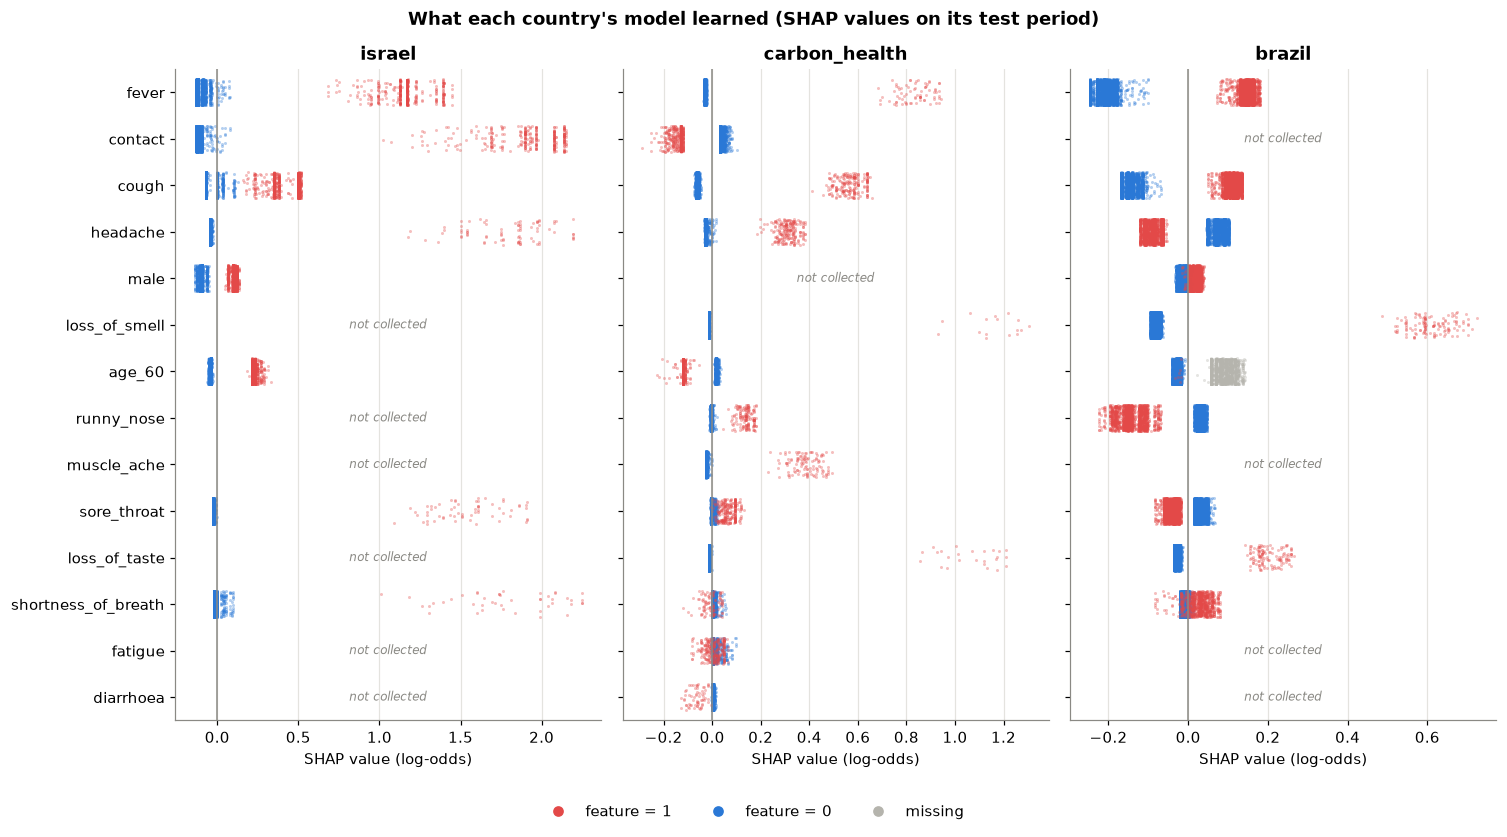

In [23]:
models = {name: sp.SymptomModel(features="all", missing="absent", n_models=5).fit(tr) for name, (tr, te) in SPLITS.items()}
shap_expl = {name: model.shap_values(SPLITS[name][1]) for name, model in models.items()}
sp.plot_shap_grid(shap_expl, max_points=6000, suptitle="What each country's model learned (SHAP values on its test period)");

- **Israel** matches the paper's Fig. 2 pattern: contact and fever have the largest effects; headache, sore throat and shortness of breath have big effects for the few people who report them; sex is small but consistent (see `notebook.ipynb` §14).
- **Carbon Health** looks quite different:
  - Loss of smell and taste have the largest per-person effects, followed by fever and cough.
  - **Contact = 1 pushes risk *down*.** People reporting possible exposure were *less* likely to test positive. That fits "worried well" coming in for a test after a scare.
  - Age ≥ 60 also pushes down, plausibly because older people were more cautious.
  - Headache, sore throat and shortness of breath matter far less than in Israel.
- **Brazil** has much smaller effects overall (note the scale):
  - Fever, cough and loss of smell/taste push up.
  - Headache, runny nose and sore throat push *down*: among people who are all ill, cold-like symptoms suggest something other than COVID.
  - Grey points are missing age, which pushes slightly up.

## 4.3 Train on one country, test on another

`sp.compare` trains on each dataset's training period, then tests every model on every dataset's **test period** (`unseen_on="test"`), so each column compares models on exactly the same tests. "within" = the dataset's own model; "unseen" = a model from another country. Features are restricted to those all datasets share.

In [24]:
cross = sp.compare(DATASETS, splits=SPLITS, missing="absent", n_models=5, bootstrap=200, unseen_on="test")
print("Features used:", cross.attrs["features"])
display(sp.pivot(cross, "auroc").style.format("{:.3f}").background_gradient(cmap="Blues", vmin=0.5, vmax=1)
        .set_caption("auROC: rows = trained on, columns = tested on"))
cross[["train", "test", "kind", "n", "prevalence", "auroc", "auroc_lo", "auroc_hi", "auprc"]].round(3)

Features used: ['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'headache', 'age_60']


test,israel,carbon_health,brazil
train,,,
brazil,0.714,0.607,0.644
carbon_health,0.770,0.679,0.682
israel,0.795,0.678,0.687


,train,test,kind,n,prevalence,auroc,auroc_lo,auroc_hi,auprc
0,israel,israel,within,47401,0.076,0.795,0.786,0.805,0.491
1,israel,carbon_health,unseen,49586,0.007,0.678,0.649,0.706,0.028
2,israel,brazil,unseen,8343,0.470,0.687,0.677,0.699,0.606
3,carbon_health,carbon_health,within,49586,0.007,0.679,0.648,0.707,0.044
4,carbon_health,israel,unseen,47401,0.076,0.770,0.762,0.778,0.318
5,carbon_health,brazil,unseen,8343,0.470,0.682,0.671,0.693,0.607
6,brazil,brazil,within,8343,0.470,0.644,0.633,0.655,0.579
7,brazil,israel,unseen,47401,0.076,0.714,0.704,0.724,0.224
8,brazil,carbon_health,unseen,49586,0.007,0.607,0.578,0.638,0.038


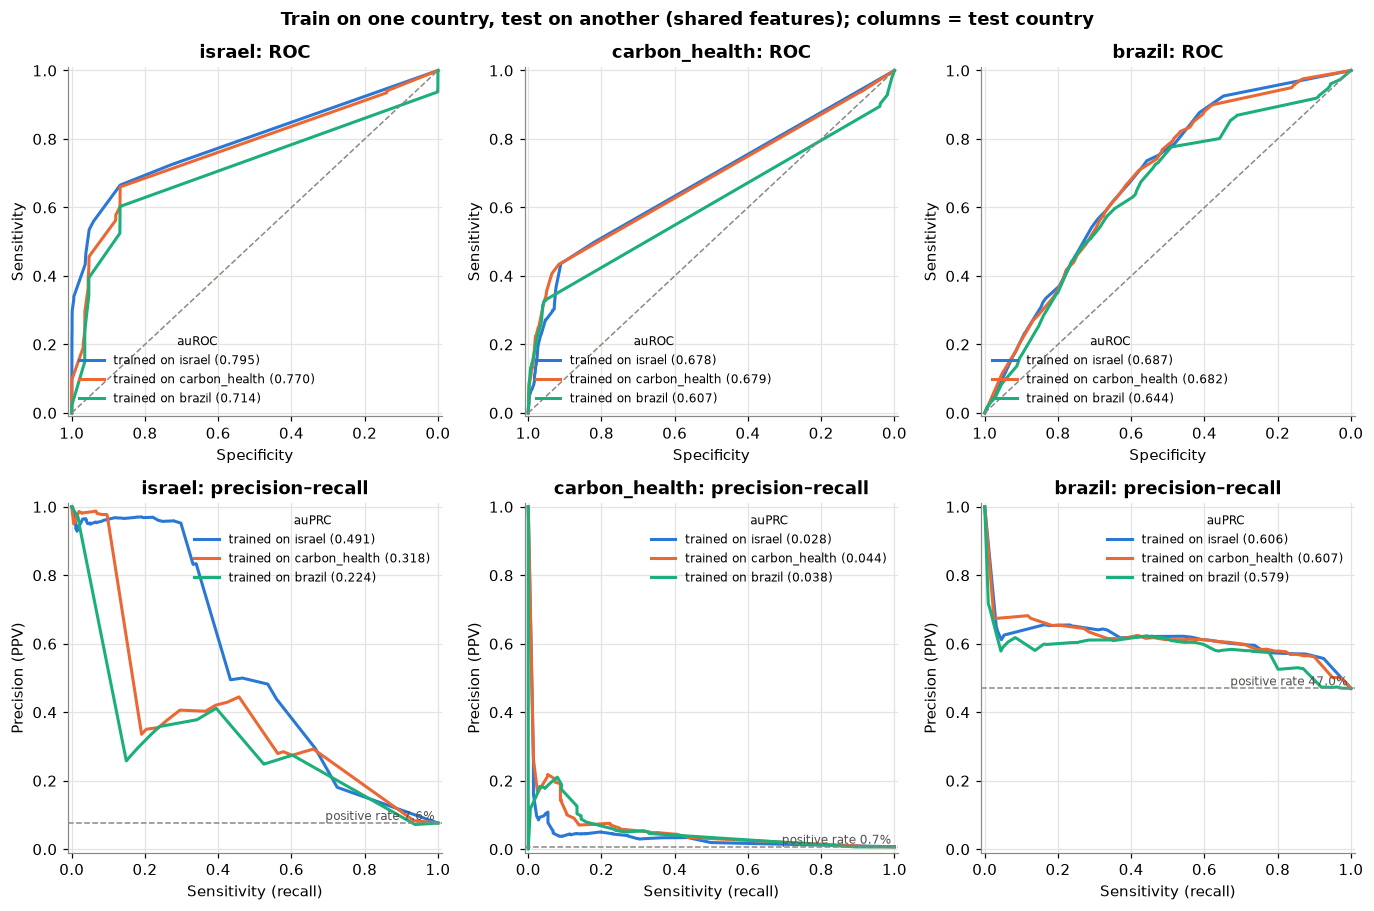

In [25]:
sp.plot_curve_grid(
    {test: {f"trained on {train}": cross.attrs["predictions"][(train, test)] for train in DATASETS} for test in DATASETS},
    colors={f"trained on {name}": COLORS[name] for name in DATASETS},
    suptitle="Train on one country, test on another (shared features); columns = test country",
);

With all three datasets the shared features shrink to the **five symptoms + age ≥ 60** (no sex, no contact). Every column compares models on the same tests:
- **Israel falls from 0.90 to 0.80 even on its own data** without contact and sex. Much of the paper's accuracy came from knowing who had been in contact with a case.
- **The US model on Israel (0.77) comes close to Israel's own reduced model (0.80).** Without contact, Israel's remaining signal is mostly "has symptoms", which the US data teaches too.
- **On US data, the Israeli model (0.68) equals the US's own model (0.68)** with these features. The US advantage in 4.1 came from features Israel never collected (loss of smell/taste and the other extras).
- **Brazil's 2022 test period is predicted better by the Israeli (0.69) and US (0.68) models than by Brazil's own (0.64).** That's the drift from 4.1: Brazil's 2020–21 data misleads on 2022.
- **Brazil's model transfers worst** (0.71 on Israel, 0.61 on the US). Trained on a population that is all ill, it learns to separate COVID from other illnesses, not ill from healthy.
- **The precision–recall panels** make the Israel gap clearer. Its own model keeps ~95% precision up to a third of positives found, while outside models drop off after 10–20%.

## 4.4 Pooling: one model for the countries it was trained on

Instead of one model per country, train **one model on all training periods combined** (`sp.pool`) and test it on each country's test period. Options compared:

- **specialist:** trained on that country alone, with all its features (the 4.1 baseline)
- **pooled, common features:** only features every dataset has
- **pooled, all features:** every feature any dataset has; NaN where a country never collected it
- **pooled, all features, balanced:** as above, with each dataset given equal total weight (`sample_weight="balance_sources"`), so the largest doesn't dominate

In [26]:
pooled_train = sp.pool({name: tr for name, (tr, te) in SPLITS.items()})
common = sp.common_features(*DATASETS.values())
pooled_models = {
    "pooled, common features": sp.SymptomModel(features=common, missing="absent", n_models=5).fit(pooled_train),
    "pooled, all features": sp.SymptomModel(features="all", missing="absent", n_models=5).fit(pooled_train),
    "pooled, all features, balanced": sp.SymptomModel(features="all", missing="absent", n_models=5)
        .fit(pooled_train, sample_weight="balance_sources"),
}
rows, pool_preds = [], {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # pooled models see features some test sets never collected; that's expected
    for name, (tr, te) in SPLITS.items():
        pool_preds[(name, "specialist")] = (te.y.values, models[name].predict(te))
        for mname, m in pooled_models.items():
            pool_preds[(name, mname)] = (te.y.values, m.predict(te.assign(source=name)))
        r = models[name].evaluate(te, bootstrap=200)
        rows.append({"test": name, "model": "specialist", "auroc": r.auroc, "lo": r.auroc_lo, "hi": r.auroc_hi,
                     "mean predicted": r.mean_predicted, "actual rate": r.prevalence})
        for mname, m in pooled_models.items():
            r = m.evaluate(te.assign(source=name), bootstrap=200)
            rows.append({"test": name, "model": mname, "auroc": r.auroc, "lo": r.auroc_lo, "hi": r.auroc_hi,
                         "mean predicted": r.mean_predicted, "actual rate": r.prevalence})
pooling = pd.DataFrame(rows)
print("Training rows per source:", pooled_train.source.value_counts().to_dict())
pooling.pivot(index="model", columns="test", values="auroc").reindex(["specialist", *pooled_models]).style.format("{:.3f}")\
    .set_caption("auROC on each country's test period")

Training rows per source: {'brazil': 89752, 'israel': 51831, 'carbon_health': 44409}


test,brazil,carbon_health,israel
model,,,
specialist,0.636,0.708,0.901
"pooled, common features",0.691,0.678,0.777
"pooled, all features",0.639,0.704,0.901
"pooled, all features, balanced",0.642,0.704,0.901


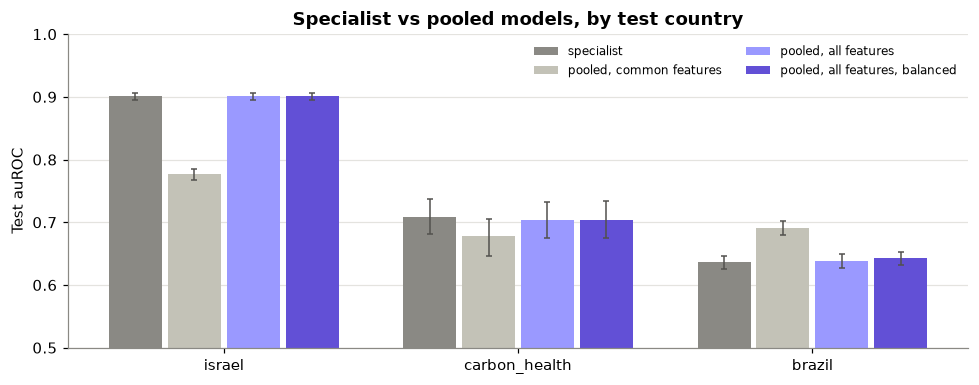

In [27]:
model_order = ["specialist", *pooled_models]
fig, ax = plt.subplots(figsize=(9, 3.6))
tests = list(SPLITS)
width = 0.8 / len(model_order)
shades = [GREY, "#c3c2b7", "#9a99ff", "#6250d6"]
for j, mname in enumerate(model_order):
    d = pooling[pooling.model == mname].set_index("test").reindex(tests)
    x = np.arange(len(tests)) + (j - (len(model_order) - 1) / 2) * width
    ax.bar(x, d.auroc - 0.5, bottom=0.5, width=width * 0.9, color=shades[j], label=mname)
    ax.errorbar(x, d.auroc, yerr=[d.auroc - d.lo, d.hi - d.auroc], fmt="none", ecolor="#52514e", capsize=2, linewidth=1)
ax.set_xticks(range(len(tests)), tests)
ax.set_ylim(0.5, 1)
ax.set_ylabel("Test auROC")
ax.set_title("Specialist vs pooled models, by test country")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncol=2, fontsize=8, loc="upper right")
plt.tight_layout()

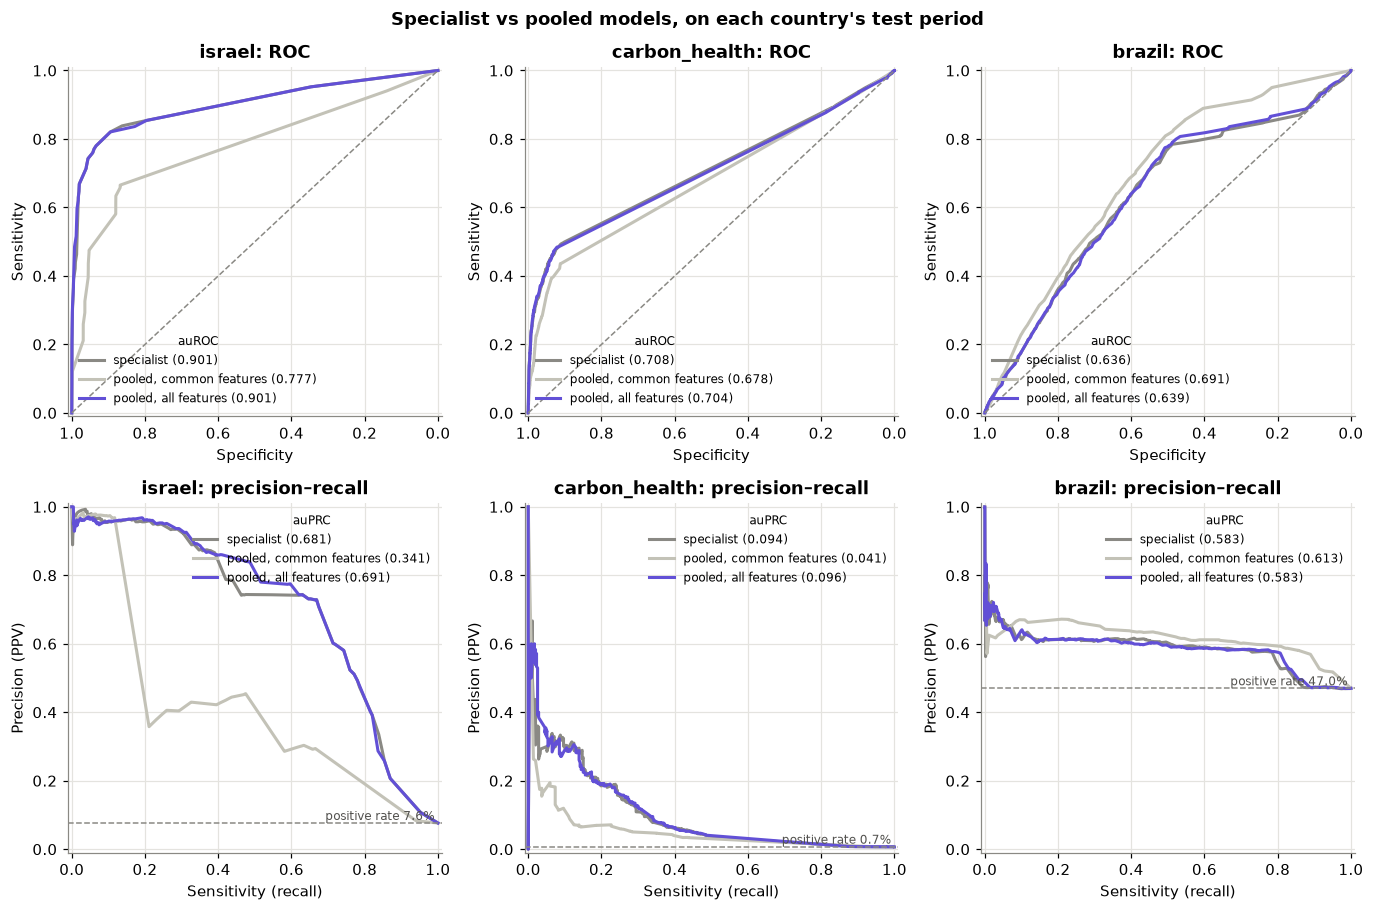

In [28]:
curve_models = ["specialist", "pooled, common features", "pooled, all features"]   # balanced ≈ unbalanced, omitted
sp.plot_curve_grid(
    {name: {m: pool_preds[(name, m)] for m in curve_models} for name in SPLITS},
    colors=dict(zip(curve_models, [GREY, "#c3c2b7", "#6250d6"])),
    suptitle="Specialist vs pooled models, on each country's test period",
);

- **Pooling with all features matches each specialist** (Israel 0.901, Carbon Health 0.704, Brazil 0.64), so one model can serve all three countries as well as three separate models.
- **Restricting to shared features** costs Israel heavily (0.78: no contact or sex) and Carbon Health a little (0.68: no extra symptoms), but **helps Brazil: 0.69 vs 0.64**. Brazil's own training data is misleading for 2022 (4.1), and learning from other countries' cough/fever patterns acts as a counterweight.
- **The curves** confirm it: pooled-all-features (dark purple) lies on top of each specialist, while pooled-common is visibly lower for Israel and higher for Brazil.
- **Balancing barely matters** (≤0.003). Brazil's training set is the largest (90k rows), but not by enough to swamp the others.

**Caveat:** matching the specialists doesn't show that pooling has learned anything general. The pooled model can work out which country a row comes from by which features are blank (no sex → US, no smell → Israel) and act like two specialists in one. Section 4.5 tests generalisation.

## 4.5 Pooling: does it help on a country it has never seen?

4.4 only tests countries the pooled model was trained on. A pooled model may simply learn to recognise each country (for example from which features are blank) and act like separate specialists. The honest test of "works for any country" is **leave-one-out**: pool every *other* country, then test on the one left out (`sp.leave_one_out`).

In [29]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    loo_runs = {features: sp.leave_one_out(DATASETS, splits=SPLITS, features=features, missing="absent", n_models=5, bootstrap=200)
                for features in ["common", "all"]}
loo = pd.concat(loo_runs, names=["feature set"]).reset_index(level=0)
loo = loo.merge(within.query("features.str.startswith('all') and missing == 'absent'")[["dataset", "auroc"]]
                .rename(columns={"dataset": "held_out", "auroc": "specialist auroc"}), on="held_out")

# For comparison: each single *other* country on its own (shared features, same test period), from 4.3
singles = {held: {o: cross.query("train == @o and test == @held").auroc.item() for o in DATASETS if o != held}
           for held in DATASETS}
loo["best single other"] = loo.held_out.map(lambda h: max(singles[h].values()))
loo["worst single other"] = loo.held_out.map(lambda h: min(singles[h].values()))
loo[["held_out", "trained_on", "feature set", "features", "auroc", "auroc_lo", "auroc_hi",
     "best single other", "worst single other", "specialist auroc"]].round(3)

,held_out,trained_on,feature set,features,auroc,auroc_lo,auroc_hi,best single other,worst single other,specialist auroc
0,israel,carbon_health + brazil,common,6,0.745,0.735,0.755,0.770,0.714,0.901
1,carbon_health,israel + brazil,common,6,0.678,0.647,0.706,0.678,0.607,0.708
2,brazil,israel + carbon_health,common,6,0.693,0.683,0.704,0.687,0.682,0.636
3,israel,carbon_health + brazil,all,14,0.608,0.596,0.621,0.770,0.714,0.901
4,carbon_health,israel + brazil,all,11,0.666,0.640,0.692,0.678,0.607,0.708
5,brazil,israel + carbon_health,all,14,0.690,0.678,0.701,0.687,0.682,0.636


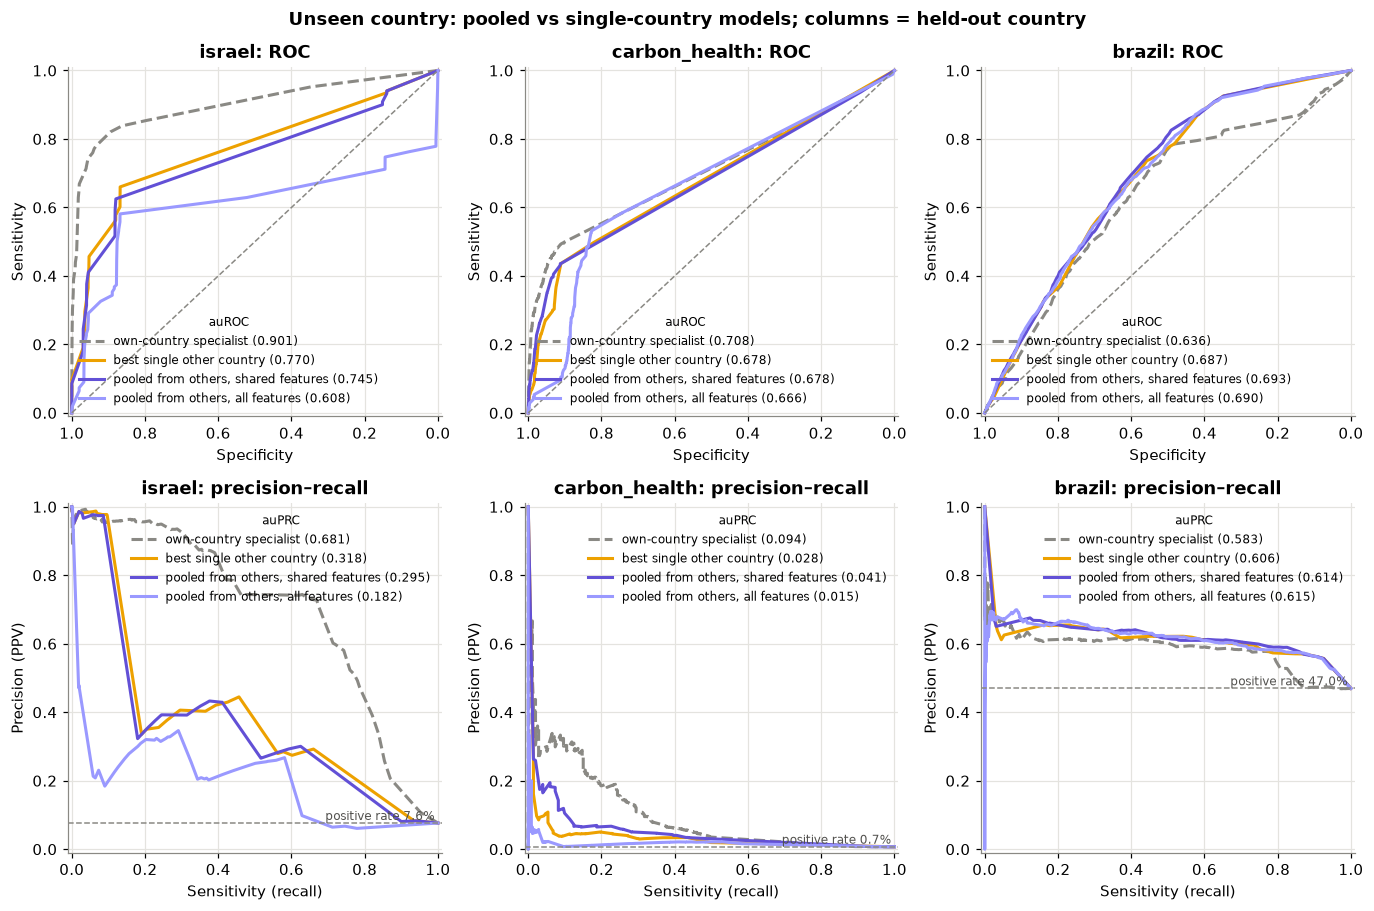

In [30]:
LOO_COMMON, LOO_ALL, BEST_OTHER, OWN = ("pooled from others, shared features", "pooled from others, all features",
                                        "best single other country", "own-country specialist")
panels = {}
for held in DATASETS:
    best = max(singles[held], key=singles[held].get)
    panels[held] = {OWN: within_preds[(held, "all", "absent")],
                    BEST_OTHER: cross.attrs["predictions"][(best, held)],
                    LOO_COMMON: loo_runs["common"].attrs["predictions"][held],
                    LOO_ALL: loo_runs["all"].attrs["predictions"][held]}
sp.plot_curve_grid(panels, colors={OWN: GREY, BEST_OTHER: "#eda100", LOO_COMMON: "#6250d6", LOO_ALL: "#9a99ff"},
                   linestyles={OWN: "--"}, suptitle="Unseen country: pooled vs single-country models; columns = held-out country");

In the curves, nothing trained elsewhere comes close to Israel's own model at high specificity, and pooling with all features (light purple) is the worst model across Israel's whole curve. For Brazil, the outside models sit above Brazil's own model over most of the ROC curve.

**For an unseen country, use only the features everyone shares.** With `all` features, the pooled model does as well or worse everywhere, and much worse on Israel (0.61 vs 0.75). Trained on Carbon Health + Brazil, it learned rules involving features that only one of them has. It also learned to tell the two apart by which features are blank, and Israel's pattern of blanks matches neither. This confirms the concern from 4.4: with mismatched features, a pooled model memorises sources rather than generalising.

**Pooling ≈ the best single source, without having to know which that is.** With shared features:

| Held out | Pooled from the other two | Best single other | Worst single other |
|---|---|---|---|
| Israel | 0.745 | 0.770 (Carbon Health) | 0.714 (Brazil) |
| Carbon Health | 0.678 | 0.678 (Israel) | 0.607 (Brazil) |
| Brazil | 0.693 | 0.687 (Israel) | 0.682 (Carbon Health) |

Pooling never picks the worst source, roughly matches the best, and beats every single source for Brazil. For a new country, where we can't know in advance which existing dataset is most similar, that's the practical argument for pooling.

**A model from elsewhere is still well short of a home-grown one for Israel and Carbon Health**, but better for Brazil (0.69 vs 0.64), because of Brazil's own drift between years.

## 4.6 How much of the paper's 0.90 is the contact flag?

The paper's discussion of bias focuses on the symptoms (headache, sore throat, shortness of breath). But the other two countries reach only ~0.64–0.71, and 4.3 showed Israel falling from 0.90 to 0.80 once contact and sex were removed. So which feature is Israel's accuracy really built on? First, remove features one at a time on the paper's own split:

In [31]:
isr_tr, isr_te = SPLITS["israel"]
CORE = list(sp.CORE_FEATURES)
BIASED = ["headache", "sore_throat", "shortness_of_breath"]
feature_sets = {
    "all 8 (paper)": CORE,
    "without sex": [f for f in CORE if f != "male"],
    "without the 3 biased symptoms": [f for f in CORE if f not in BIASED],
    "without contact": [f for f in CORE if f != "contact"],
    "without contact or the 3 biased symptoms": [f for f in CORE if f not in BIASED + ["contact"]],
    "contact only": ["contact"],
}
rows = []
for label, feats in feature_sets.items():
    r = sp.SymptomModel(features=feats, n_models=5).fit(isr_tr).evaluate(isr_te, bootstrap=300)
    rows.append({"features": label, "n": len(feats), "auROC": r.auroc, "lo": r.auroc_lo, "hi": r.auroc_hi,
                 "above chance": r.auroc - 0.5})
ablation = pd.DataFrame(rows).set_index("features")
ablation.style.format({"auROC": "{:.3f}", "lo": "{:.3f}", "hi": "{:.3f}", "above chance": "{:+.3f}"})

,n,auROC,lo,hi,above chance
features,,,,,
all 8 (paper),8,0.901,0.895,0.907,+0.401
without sex,7,0.895,0.889,0.901,+0.395
without the 3 biased symptoms,5,0.872,0.864,0.879,+0.372
without contact,7,0.799,0.790,0.808,+0.299
without contact or the 3 biased symptoms,4,0.741,0.731,0.751,+0.241
contact only,1,0.729,0.720,0.737,+0.229


In [32]:
c = isr_te.contact == 1
print(f"Test week: {c.mean():.1%} of tests were known contacts, but they were {isr_te.loc[c, 'y'].sum() / isr_te.y.sum():.0%} of positives.")
print(f"Positivity: {isr_te.loc[c, 'y'].mean():.0%} for contacts vs {isr_te.loc[~c, 'y'].mean():.1%} for everyone else.")

Test week: 5.2% of tests were known contacts, but they were 47% of positives.
Positivity: 69% for contacts vs 4.2% for everyone else.


**Contact is the single biggest ingredient, by a long way:**
- **Removing contact costs 0.10 auROC.** Removing the three "biased" symptoms costs 0.03; removing sex costs almost nothing.
- **Contact alone scores 0.73.** All seven other features together score 0.80 without it. Measured above chance (0.5), that's +0.23 for one question against +0.30 for the other seven combined: **one question is worth about three-quarters of all the others put together.**
- **Contact alone in Israel matches the full symptom models elsewhere** (US 0.71, Brazil 0.64).
- With the biased symptoms *and* contact removed, Israel scores **0.74**, in line with the other two countries. Once the parts specific to how Israel recorded its data are stripped out, the three countries converge.

**Why contact is so powerful here:** only ~5% of tests in the test week were known contacts, yet they made up ~47% of positives, with 69% positivity against 4% for everyone else. This "feature" is `test_indication`: the official reason the person was tested. It records that **contact tracing sent them**, so it reflects how well Israel's 2020 contact-tracing system worked rather than anything a patient would tell you. That's legitimately useful information where such a system exists, but it isn't a symptom and it didn't transfer: the US's self-reported "possible exposure" carried no signal (3.2).

### How many questions do you actually need?

`sp.forward_selection` adds one feature at a time, each time choosing whichever helps most. The choice is made on a held-out part of the *training* data, never the test period, and each step is then scored on the test period. Run for each country with all its features:

israel                   carbon_health             \
                    added test_auroc                added test_auroc   
step                                                                   
1                 contact      0.729                cough      0.612   
2                   fever      0.828             headache      0.649   
3                   cough      0.865                fever      0.674   
4             sore_throat      0.875        loss_of_smell      0.699   
5                headache      0.881              contact      0.697   
6                    male      0.893          muscle_ache      0.698   
7                  age_60      0.895           runny_nose      0.702   
8     shortness_of_breath      0.901              fatigue      0.703   
9                     NaN        NaN            diarrhoea      0.702   
10                    NaN        NaN        loss_of_taste      0.708   
11                    NaN        NaN  shortness_of_breath      0.706   
12                    NaN        NaN          sore_throat      0.709   
13                    NaN        NaN               age_60      0.706   

                   brazil             
                    added test_auroc  
step                                  
1                   fever      0.621  
2           loss_of_smell      0.627  
3                headache      0.592  
4                   cough      0.657  
5              runny_nose      0.657  
6                  age_60      0.628  
7                    male      0.634  
8             sore_throat      0.630  
9     shortness_of_breath      0.634  
10          loss_of_taste      0.635  
11                    NaN        NaN  
12                    NaN        NaN  
13                    NaN        NaN

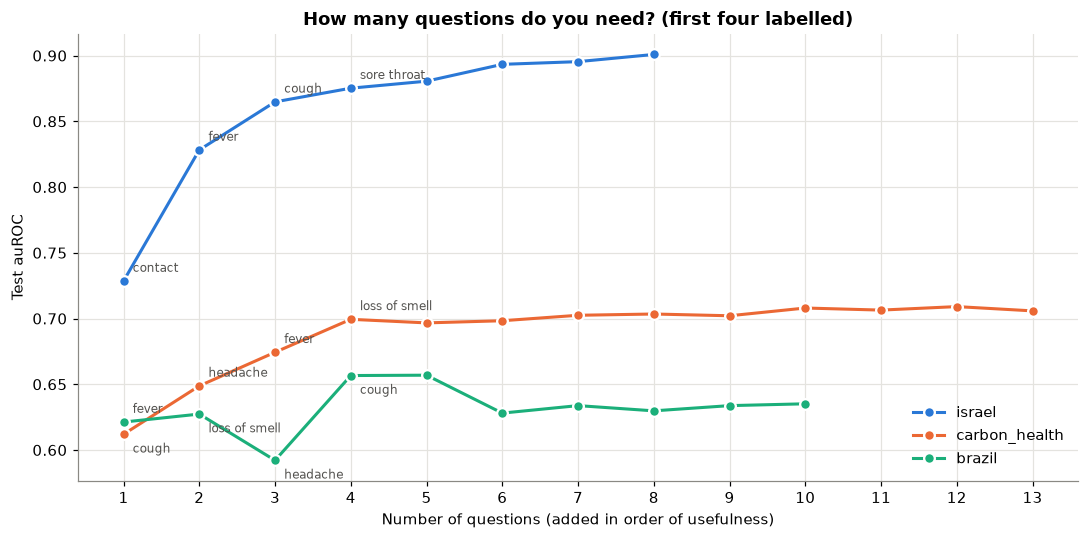

In [33]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    selection = {name: sp.forward_selection(tr, te, n_models=3, missing="absent") for name, (tr, te) in SPLITS.items()}

fig, ax = plt.subplots(figsize=(10, 5))
for name, fs in selection.items():
    ax.plot(fs.step, fs.test_auroc, color=COLORS[name], linewidth=2, marker="o", markersize=7,
            markeredgecolor="white", markeredgewidth=1.5, label=name)
    for r in fs.head(4).itertuples():
        ax.annotate(r.added.replace("_", " "), (r.step, r.test_auroc), textcoords="offset points", xytext=(6, 6 if name == "israel" or (name == "brazil") == (r.step == 1) else -12),
                    fontsize=8, color="#52514e")
ax.set_xlabel("Number of questions (added in order of usefulness)")
ax.set_ylabel("Test auROC")
ax.set_xticks(range(1, max(len(f) for f in selection.values()) + 1))
ax.set_title("How many questions do you need? (first four labelled)")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()

pd.concat({name: fs.set_index("step")[["added", "test_auroc"]] for name, fs in selection.items()}, axis=1).round(3)

- **Israel:** contact → fever → cough reaches **0.87 with three questions**, ~96% of the full 0.90, and none of them is a "biased" symptom.
- **US:** cough, headache, fever and loss of smell reach **0.70 with four questions**, the same as all 13 (0.71). Contact never makes the cut.
- **Brazil:** the best score comes from **four questions (0.66)**, and adding more makes it *worse* (0.64 with all ten), because the extra features encode 2020–21 patterns that no longer held in 2022 (4.1). The dip at step 3 (headache) is the same drift: chosen on training-period data, it doesn't help in 2022.
- **In every country, 3–4 questions capture essentially everything.** What differs between countries is *which* questions, and how high the ceiling is.

---
# 5. Summary

| | Israel (paper) | Carbon Health (US) | Brazil (Acre, under-55s) |
|---|---|---|---|
| Tests used / positivity | 256k / 5.3% | 94k / 1.4% | 98k / 43% |
| Who was tested | mixed: contacts, travellers, symptomatic | walk-in clinics → mass screening | people with flu-like illness |
| Symptoms recorded before result? | No: more thorough for positives | Yes, at the visit | Yes, at notification |
| % positive among those with headache | 95% | 5% | 42% (base rate 43%) |
| Positives with none of the 5 symptoms | 36% | 52% | 7% |
| Best within-dataset auROC | 0.90 | 0.71 (all features, `missing="absent"`) | 0.64 (0.69 with pooling) |
| Strongest signals | contact, fever, the "biased" symptoms | loss of smell/taste, fever, cough | fever, cough, loss of smell (all weak) |

**Findings so far**
1. **The paper's ~0.90 doesn't carry over.** Where symptoms were recorded before the result, the same method reaches ~0.64–0.71.
2. **Israel's 0.90 rests mostly on the contact flag, not on symptoms** (4.6). Contact alone scores 0.73, worth about three-quarters of the other seven features combined. Without contact and the biased symptoms, Israel scores 0.74, in line with the other countries.
3. **Who gets tested sets the ceiling.** Screening populations (Carbon Health) contain many symptomless positives; symptomatic-only populations (Brazil) make symptoms nearly useless for telling COVID from other illnesses. Symptom questions work best somewhere in between.
4. **How missing values are handled matters as much as the model.** In Carbon Health, blanks tracked the testing setting and flipped meaning over time. `missing="absent"` recovers ~0.1 auROC.
5. **Features don't mean the same thing everywhere,** and they drift. "Contact" is a strong positive signal in Israel and a slight negative one in the US. Loss of smell was the strongest symptom until Omicron made it rare.
6. **Models transfer poorly between countries** (~0.54–0.78).
7. **Pooling works for known countries if all features are kept**, matching each specialist. For an **unseen** country, pooling on **shared features** roughly matches the best single source without needing to know which that is, while pooling on all features can fail badly.

8. **3–4 questions capture almost all the signal** in every country (4.6).

**Caveats:** "Brazil" is one state and only under-55s; Carbon Health is one US clinic chain; all three are early in the pandemic (2020–22).

**Possible next steps:**
- Recalibrate pooled models per country, since positivity ranges from 1% to 43%.
- Add `time` handling: retrain on recent data only, given the drift.
- Seek the gated UK datasets (ONS Infection Survey, REACT-1). These were random population samples, which would test the method without targeted testing at all.

---
# 6. Presentation assets and takeaways

Slide-ready versions of the key results. Each chart is computed from the results above and saved as a high-resolution PNG in `assets/alternative-datasets/`. Charts use large fonts and a white background for projection.

In [34]:
ASSETS = Path("assets/alternative-datasets")
ASSETS.mkdir(parents=True, exist_ok=True)
DISPLAY = {"israel": "Israel\n(paper's data)", "carbon_health": "US\n(Carbon Health)", "brazil": "Brazil\n(Acre)"}
SLIDE_STYLE = {"font.size": 14, "axes.titlesize": 17, "axes.labelsize": 14, "xtick.labelsize": 13, "ytick.labelsize": 13,
               "legend.fontsize": 12, "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"}

def save(fig, name):
    path = ASSETS / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"saved {path}")

### Asset 1: the headline. Same method, three countries

saved assets/alternative-datasets/1_same_method_three_countries.png


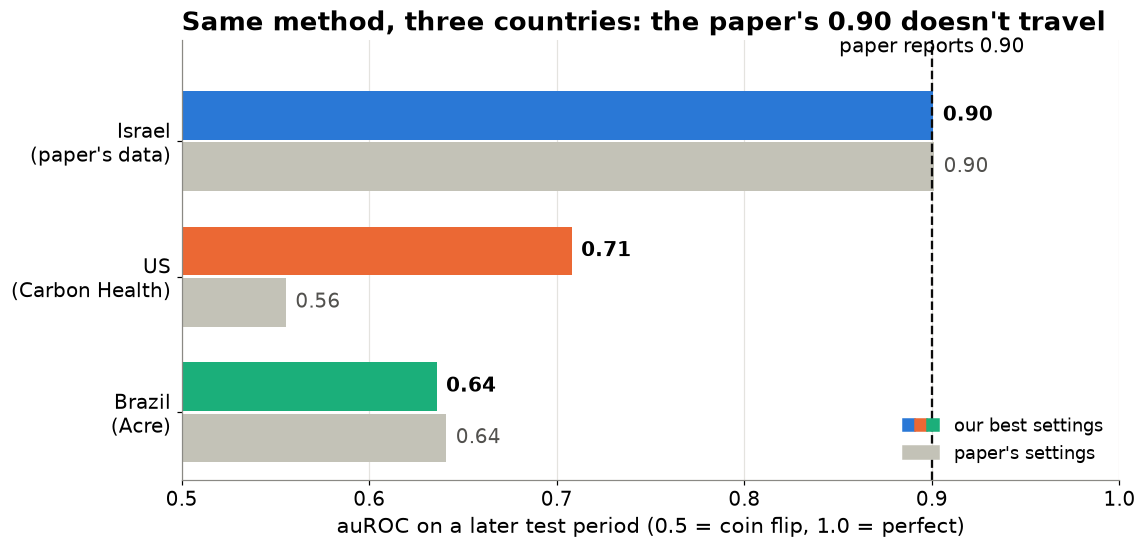

In [35]:
with plt.rc_context(SLIDE_STYLE):
    names = list(SPLITS)
    paper_cfg = within.query("features.str.startswith('core') and missing == 'native'").set_index("dataset").auroc
    best_cfg = within.query("features.str.startswith('all') and missing == 'absent'").set_index("dataset").auroc
    fig, ax = plt.subplots(figsize=(11, 5.2))
    y = np.arange(len(names))
    ax.barh(y + 0.19, paper_cfg[names] - 0.5, left=0.5, height=0.36, color="#c3c2b7", label="paper's settings")
    ax.barh(y - 0.19, best_cfg[names] - 0.5, left=0.5, height=0.36, color=[COLORS[n] for n in names], label="our best settings")
    for i, n in enumerate(names):
        ax.text(paper_cfg[n] + 0.005, i + 0.19, f"{paper_cfg[n]:.2f}", va="center", fontsize=13, color="#52514e")
        ax.text(best_cfg[n] + 0.005, i - 0.19, f"{best_cfg[n]:.2f}", va="center", fontsize=13, fontweight="bold")
    ax.axvline(0.90, color="#0b0b0b", linestyle="--", linewidth=1.5)
    ax.text(0.90, -0.62, "paper reports 0.90", ha="center", va="bottom", fontsize=13)
    ax.set_yticks(y, [DISPLAY[n] for n in names])
    ax.invert_yaxis()
    ax.set_xlim(0.5, 1.0)
    ax.set_xlabel("auROC on a later test period (0.5 = coin flip, 1.0 = perfect)")
    ax.set_title("Same method, three countries: the paper's 0.90 doesn't travel", loc="left")
    ax.grid(axis="y", visible=False)
    from matplotlib.legend_handler import HandlerTuple
    from matplotlib.patches import Patch
    ax.legend([tuple(Patch(color=COLORS[n]) for n in names), Patch(color="#c3c2b7")],
              ["our best settings", "paper's settings"],
              handler_map={tuple: HandlerTuple(ndivide=None, pad=0)}, frameon=False, loc="lower right")
    ax.set_ylim(len(names) - 0.5, -0.75)
    save(fig, "1_same_method_three_countries")
    plt.show()

### Asset 2: why. Symptoms that looked decisive in Israel barely register elsewhere

saved assets/alternative-datasets/2_symptom_signal_by_country.png


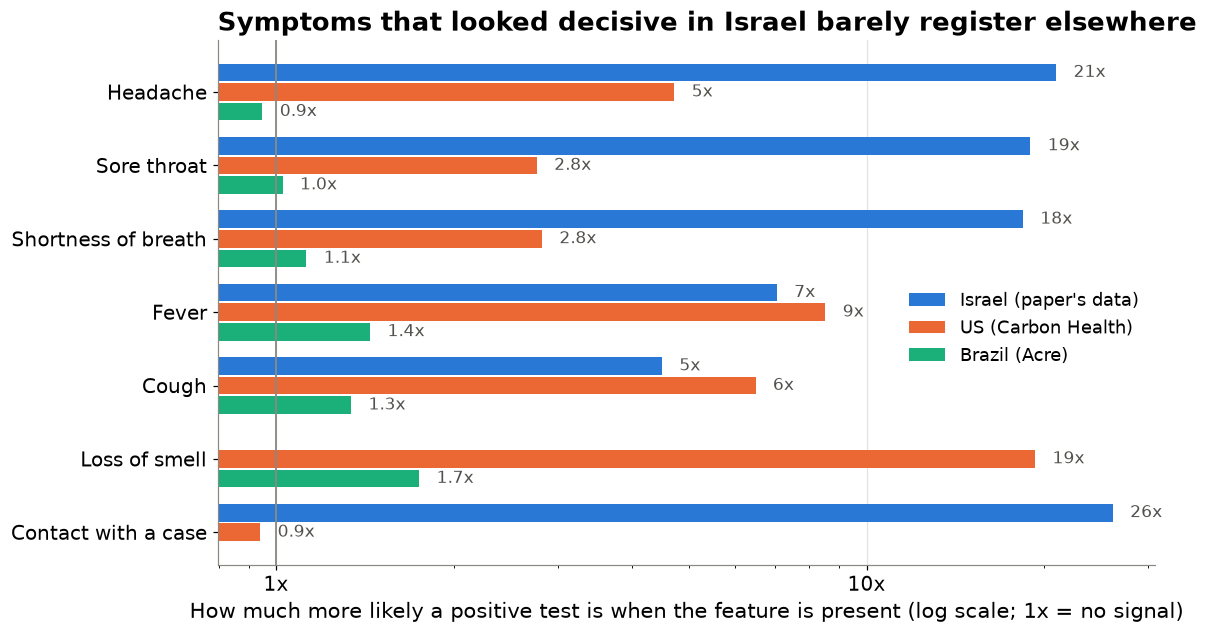

In [36]:
with plt.rc_context(SLIDE_STYLE):
    feats = ["headache", "sore_throat", "shortness_of_breath", "fever", "cough", "loss_of_smell", "contact"]
    nice = {"headache": "Headache", "sore_throat": "Sore throat", "shortness_of_breath": "Shortness of breath",
            "fever": "Fever", "cough": "Cough", "loss_of_smell": "Loss of smell", "contact": "Contact with a case"}
    L = lifts.loc[feats]
    fig, ax = plt.subplots(figsize=(11, 6.2))
    n = len(DATASETS)
    h = 0.8 / n
    for j, name in enumerate(DATASETS):
        off = (j - (n - 1) / 2) * h
        ax.barh(np.arange(len(L)) + off, L[name], height=h * 0.9, color=COLORS[name], label=DISPLAY[name].replace("\n", " "))
        for i, v in enumerate(L[name]):
            if pd.notna(v):
                ax.text(v * 1.07, i + off, f"{v:.0f}x" if v >= 3 else f"{v:.1f}x", va="center", fontsize=11, color="#52514e")
    ax.set_xscale("log")
    ax.axvline(1, color=GREY, linewidth=1.2)
    ax.set_yticks(range(len(L)), [nice[f] for f in feats])
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}x"))
    ax.set_xlabel("How much more likely a positive test is when the feature is present (log scale; 1x = no signal)")
    ax.set_title("Symptoms that looked decisive in Israel barely register elsewhere", loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, loc="center right", bbox_to_anchor=(1.0, 0.45))
    save(fig, "2_symptom_signal_by_country")
    plt.show()

### Asset 3: generalisation. Who can predict whom?

saved assets/alternative-datasets/3_cross_country_matrix.png


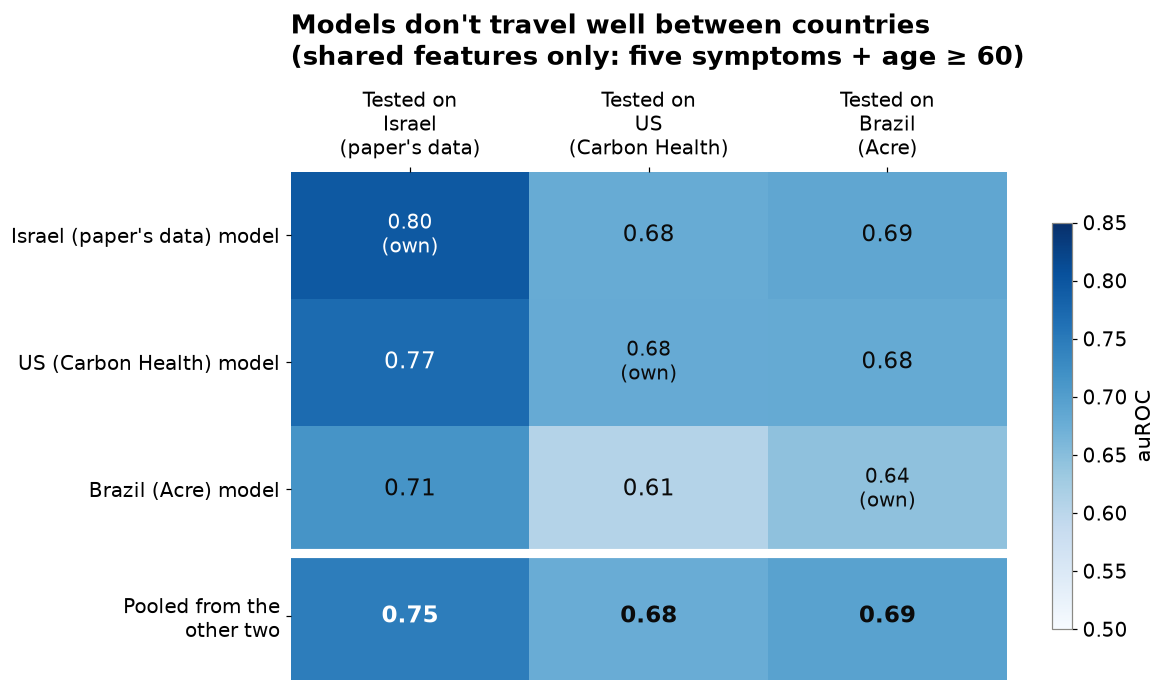

In [37]:
with plt.rc_context(SLIDE_STYLE):
    names = list(DATASETS)
    M = sp.pivot(cross, "auroc").reindex(index=names, columns=names)
    pooled_row = loo_runs["common"].set_index("held_out").auroc.reindex(names)
    M.loc["pooled"] = pooled_row
    row_labels = [f"{DISPLAY[n]} model".replace("\n", " ") for n in names] + ["Pooled from the\nother two"]
    fig, ax = plt.subplots(figsize=(10.5, 6))
    im = ax.imshow(M.values, cmap="Blues", vmin=0.5, vmax=0.85, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.iat[i, j]
            own = i < len(names) and names[i] == names[j]
            ax.text(j, i, f"{v:.2f}" + ("\n(own)" if own else ""), ha="center", va="center", fontsize=15 if not own else 13,
                    fontweight="bold" if i == len(names) else "normal", color="white" if v > 0.72 else "#0b0b0b")
    ax.axhline(len(names) - 0.5, color="white", linewidth=6)
    ax.set_xticks(range(len(names)), [f"Tested on\n{DISPLAY[n]}" for n in names])
    ax.set_yticks(range(len(row_labels)), row_labels)
    ax.xaxis.tick_top()
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.colorbar(im, ax=ax, shrink=0.8, label="auROC")
    ax.set_title("Models don't travel well between countries\n(shared features only: five symptoms + age ≥ 60)", loc="left", pad=70)
    save(fig, "3_cross_country_matrix")
    plt.show()

### Asset 4: a hidden leak. "Not recorded" flipped meaning

saved assets/alternative-datasets/4_missing_data_flip.png


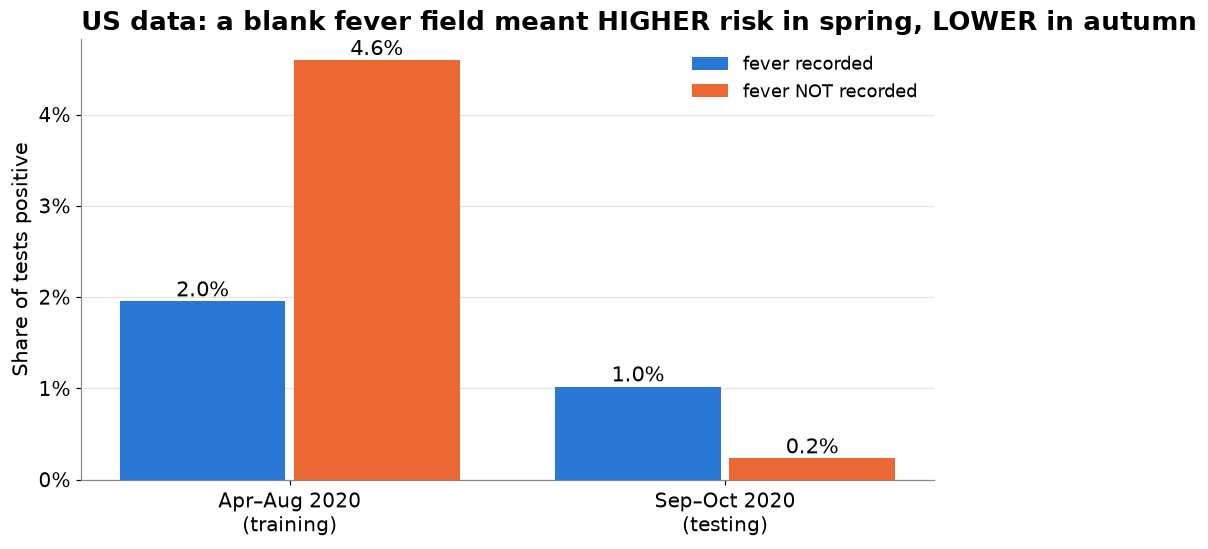

In [38]:
with plt.rc_context(SLIDE_STYLE):
    f = miss.query("dataset == 'carbon_health' and feature == 'fever'").set_index("period")
    periods = {"train": "Apr–Aug 2020\n(training)", "test": "Sep–Oct 2020\n(testing)"}
    fig, ax = plt.subplots(figsize=(10, 5.2))
    x = np.arange(2)
    rec = f.loc[list(periods), "positivity if recorded"].values
    notrec = f.loc[list(periods), "positivity if not recorded"].values
    ax.bar(x - 0.2, rec, width=0.38, color=BLUE, label="fever recorded")
    ax.bar(x + 0.2, notrec, width=0.38, color=ORANGE, label="fever NOT recorded")
    for xi, v in zip(np.r_[x - 0.2, x + 0.2], np.r_[rec, notrec]):
        ax.text(xi, v, f"{v:.1%}", ha="center", va="bottom", fontsize=14)
    ax.set_xticks(x, list(periods.values()))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_ylabel("Share of tests positive")
    ax.set_title("US data: a blank fever field meant HIGHER risk in spring, LOWER in autumn", loc="left")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False)
    save(fig, "4_missing_data_flip")
    plt.show()

### Asset 5: one model for all three countries

saved assets/alternative-datasets/5_pooled_all_countries.png


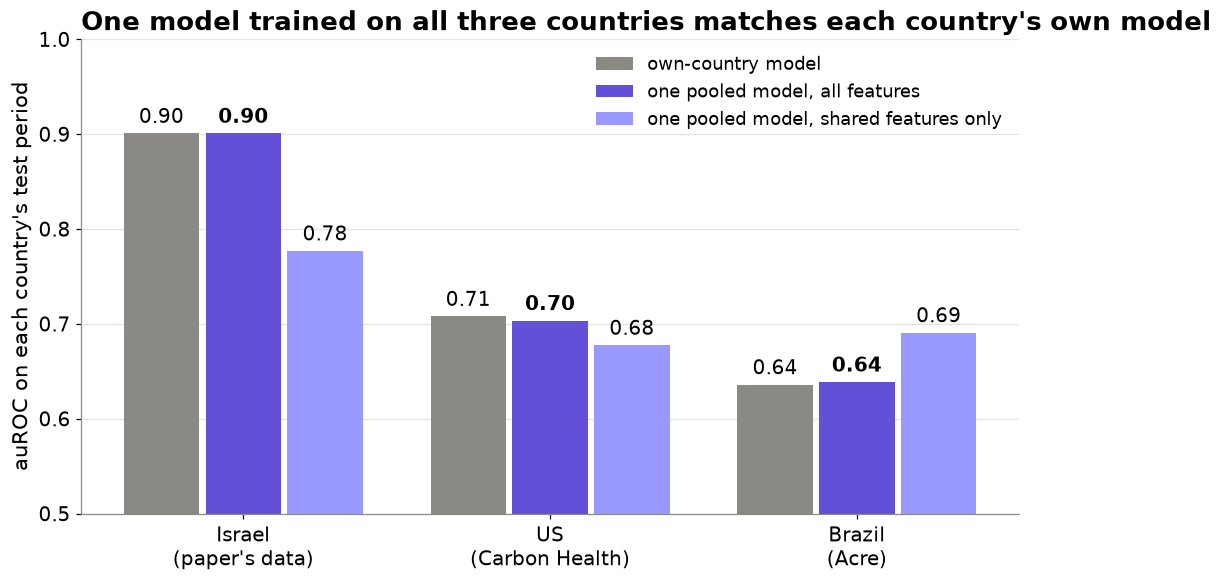

In [39]:
with plt.rc_context(SLIDE_STYLE):
    names = list(SPLITS)
    series = {"own-country model": ("specialist", GREY),
              "one pooled model, all features": ("pooled, all features", "#6250d6"),
              "one pooled model, shared features only": ("pooled, common features", "#9a99ff")}
    P = pooling.pivot(index="model", columns="test", values="auroc")
    fig, ax = plt.subplots(figsize=(11, 5.6))
    width = 0.8 / len(series)
    for k, (label, (key, color)) in enumerate(series.items()):
        x = np.arange(len(names)) + (k - (len(series) - 1) / 2) * width
        vals = P.loc[key, names].values
        ax.bar(x, vals - 0.5, bottom=0.5, width=width * 0.92, color=color, label=label)
        for xi, v in zip(x, vals):
            ax.text(xi, v + 0.006, f"{v:.2f}", ha="center", va="bottom", fontsize=13,
                    fontweight="bold" if key == "pooled, all features" else "normal")
    ax.set_xticks(range(len(names)), [DISPLAY[n] for n in names])
    ax.set_ylim(0.5, 1.0)
    ax.set_ylabel("auROC on each country's test period")
    ax.set_title("One model trained on all three countries matches each country's own model", loc="left")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, loc="upper right")
    save(fig, "5_pooled_all_countries")
    plt.show()

### Asset 6: Israel's 0.90 leans on one question

saved assets/alternative-datasets/6_contact_ablation.png


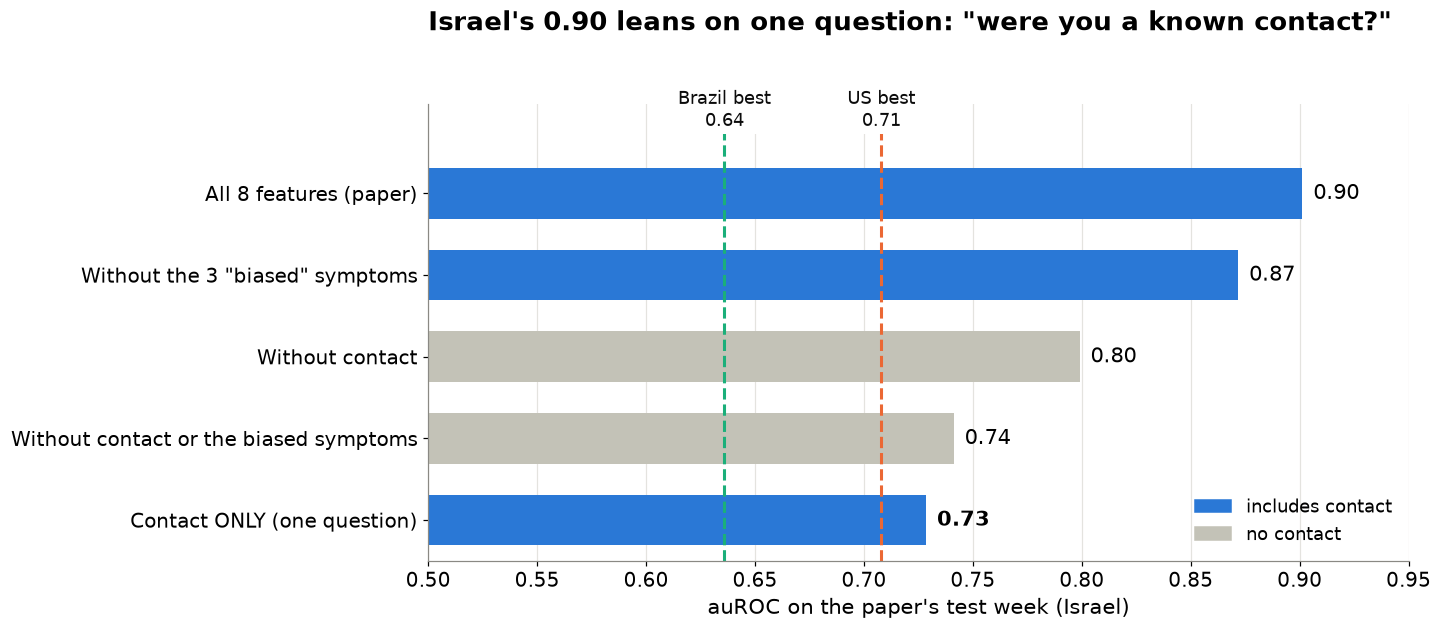

In [40]:
with plt.rc_context(SLIDE_STYLE):
    show = ["all 8 (paper)", "without the 3 biased symptoms", "without contact", "without contact or the 3 biased symptoms", "contact only"]
    nice = {"all 8 (paper)": "All 8 features (paper)", "without the 3 biased symptoms": "Without the 3 \"biased\" symptoms",
            "without contact": "Without contact", "without contact or the 3 biased symptoms": "Without contact or the biased symptoms",
            "contact only": "Contact ONLY (one question)"}
    A = ablation.loc[show]
    has_contact = ["contact" in feature_sets[s] for s in show]
    fig, ax = plt.subplots(figsize=(11.5, 5.4))
    y = np.arange(len(show))
    ax.barh(y, A.auROC - 0.5, left=0.5, height=0.62, color=[BLUE if h else "#c3c2b7" for h in has_contact])
    for i, v in enumerate(A.auROC):
        ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=14, fontweight="bold" if show[i] == "contact only" else "normal")
    ref = {"US best": (within.query("dataset == 'carbon_health' and features.str.startswith('all') and missing == 'absent'").auroc.item(), ORANGE),
           "Brazil best": (within.query("dataset == 'brazil' and features.str.startswith('all') and missing == 'absent'").auroc.item(), AQUA)}
    for label, (v, color) in ref.items():
        ax.axvline(v, color=color, linestyle="--", linewidth=2)
        ax.text(v, -0.75, f"{label}\n{v:.2f}", ha="center", va="bottom", fontsize=12, color="#0b0b0b",
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
    ax.set_yticks(y, [nice[s] for s in show])
    ax.set_ylim(len(show) - 0.5, -1.1)
    ax.set_xlim(0.5, 0.95)
    ax.set_xlabel("auROC on the paper's test week (Israel)")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=BLUE, label="includes contact"), Patch(color="#c3c2b7", label="no contact")],
              frameon=False, loc="lower right")
    ax.set_title("Israel's 0.90 leans on one question: \"were you a known contact?\"", loc="left", pad=48)
    ax.grid(axis="y", visible=False)
    save(fig, "6_contact_ablation")
    plt.show()

### Asset 7: three or four questions is enough

saved assets/alternative-datasets/7_how_many_questions.png


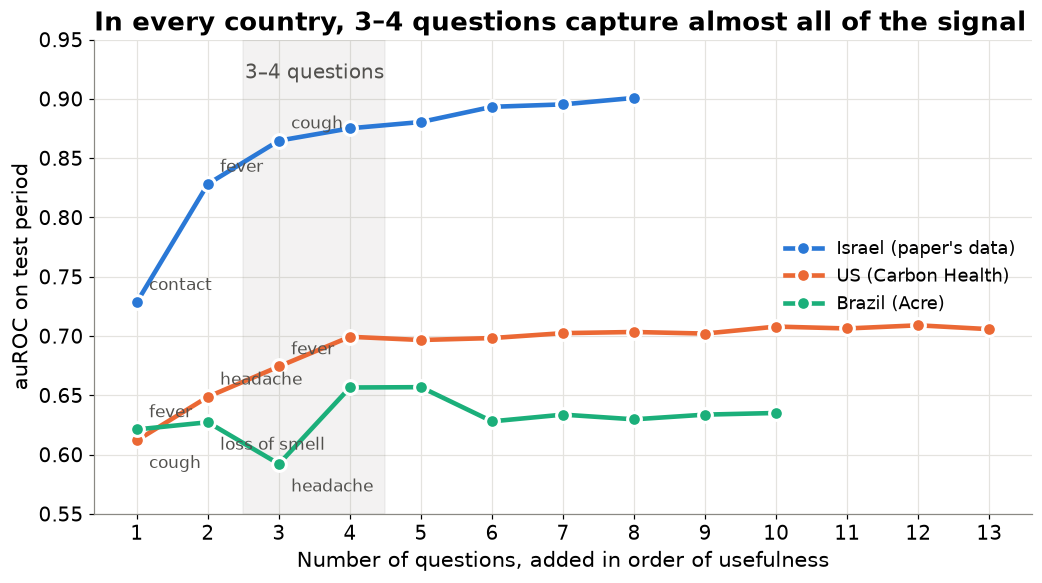

In [41]:
with plt.rc_context(SLIDE_STYLE):
    fig, ax = plt.subplots(figsize=(11, 5.6))
    for name, fs in selection.items():
        ax.plot(fs.step, fs.test_auroc, color=COLORS[name], linewidth=3, marker="o", markersize=9,
                markeredgecolor="white", markeredgewidth=2, label=DISPLAY[name].replace("\n", " "))
        for r in fs.head(3).itertuples():
            ax.annotate(r.added.replace("_", " "), (r.step, r.test_auroc), textcoords="offset points",
                        xytext=(8, 8 if name == "israel" or (name == "brazil") == (r.step == 1) else -18), fontsize=11, color="#52514e")
    ax.axvspan(2.5, 4.5, color=GREY, alpha=0.10)
    ax.text(3.5, 0.93, "3–4 questions", ha="center", va="top", fontsize=13, color="#52514e")
    ax.set_xlabel("Number of questions, added in order of usefulness")
    ax.set_ylabel("auROC on test period")
    ax.set_ylim(0.55, 0.95)
    ax.set_xticks(range(1, max(len(f) for f in selection.values()) + 1))
    ax.set_title("In every country, 3–4 questions capture almost all of the signal", loc="left")
    ax.legend(frameon=False, loc="center right")
    save(fig, "7_how_many_questions")
    plt.show()

## Suggested slides

**Slide 1: "Does the paper's approach work outside Israel?"** Asset 1 (large) + Asset 2 (small, or as a build).
- We rebuilt the paper's method as a reusable library and ran it on data from the US (94k tests) and Brazil (98k tests).
- **Israel 0.90 → US 0.71 → Brazil 0.64 auROC.** The paper's headline number doesn't travel.
- Why: in Israel, symptoms like headache were recorded almost only for confirmed cases (95% positive). Elsewhere they were recorded before the result, and their predictive power largely disappears.
- Who gets tested sets the ceiling: US screening finds many symptomless positives; Brazil only tests the already-ill.

**Optional slide 1b: "What is the paper's 0.90 really built on?"** Asset 6 (large) + Asset 7 (small).
- The paper's bias discussion focuses on symptoms, but **the biggest single ingredient is "contact"**: removing it costs 0.10 auROC, against 0.03 for the three biased symptoms.
- **Contact alone scores 0.73**, as good as the full symptom model in the US (0.71) and better than Brazil (0.64). One question is worth about three-quarters of the other seven combined.
- "Contact" is the official reason for the test, i.e. **contact tracing sent them**. Useful where tracing exists, but it isn't a symptom and didn't transfer to the US.
- Strip out contact and the biased symptoms and Israel scores **0.74**, in line with the other countries. In every country, **3–4 questions capture almost all the signal.**

**Slide 2: "What would make it work across countries?"** Asset 3 (large) + Asset 5 or Asset 4 (small).
- A model from one country scores **0.61–0.77** on another: features mean different things (e.g. "contact" is a strong signal in Israel and none in the US).
- **One model trained on all three countries** matches each country's own model (Asset 5: 0.90 / 0.70 / 0.64), as long as it can use every feature any country collected. Restricting to shared features costs Israel heavily (0.78) but helps Brazil (0.69).
- For a country it has **never seen**, pooling roughly matches the best single source, without needing to know in advance which that is. There, use only the features everyone shares.
- **How data was collected leaks into models.** In the US, a blank fever field flipped from "higher risk" to "lower risk" as testing moved to pop-up clinics. Treating blanks as "not reported" recovered ~0.1 auROC.
- Symptom profiles drift with new variants: loss of smell was the top symptom until Omicron made it rare.

## Takeaways (for speaker notes or discussion)
1. **A headline accuracy figure is a property of a dataset, not just a model.** The same code ranged from 0.64 to 0.90 depending on where and how the data was collected.
2. **Check for recording bias before trusting a feature.** A simple test, "what share of people with this symptom tested positive?", exposed the paper's biased features in seconds.
3. **Missing data is information about the process, and processes change.** Decide deliberately how blanks are treated; the default can learn a leak.
4. **Same field name ≠ same measurement.** "Contact" (Israel: official reason for test; US: self-reported possible exposure) behaved oppositely.
5. **Who is tested matters as much as what is asked.** Symptom questions discriminate best in a mixed population, and poorly in screening-only or symptomatic-only groups.
6. **Models need refreshing as the disease changes.** Training on 2021 alone beat 2020–21 for predicting 2022.
7. **Ask which feature carries the result, not just which are biased.** A one-at-a-time ablation showed the paper's accuracy rests mostly on a contact-tracing flag, not on symptoms: contact alone scores 0.73, and Israel without it converges with the other countries.
8. **Fewer questions are nearly as good.** 3–4 well-chosen questions reach almost the full score in every country; in Brazil, more questions made it worse.
9. **Build for comparison from the start.** A shared data convention (one loader per dataset) turned each new country into a one-function job and made every experiment rerunnable.

**Caveats to state:** the Brazil data is effectively one state (Acre) and under-55s only; the US data is one clinic chain; all data is 2020–22.